In [512]:
from pathlib import Path

import os

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.datasets import STL10
import time


# DO NOT use CUDA_LAUNCH_BLOCKING=1 during normal training.
# It forces synchronization after CUDA launches and hurts throughput.
os.environ.pop("CUDA_LAUNCH_BLOCKING", None)

# Allow fast Tensor Core matmuls (TF32 on supported hardware)
torch.set_float32_matmul_precision("high")


data_root = Path(os.environ["ML_DATASETS"])

train_ds = STL10(
    root=data_root,
    split="train+unlabeled",
    download=False, #already downloaded
    transform=transforms.ToTensor(),
)

test_ds = STL10(
    root=data_root,
    split="test",
    download=False, #already downloaded
    transform=transforms.ToTensor(),
)
DATA_SEED = 42

train_generator = torch.Generator()
train_generator.manual_seed(DATA_SEED)

train_dataloader = DataLoader(
    train_ds,
    shuffle=True,
    batch_size=64,
    drop_last=True,
    generator=train_generator,
)

test_dataloader = DataLoader(
    test_ds,
    batch_size=256,
    shuffle=False,
)

In [513]:
print(torch.__version__)
print(torch.version.cuda)
print(torch.cuda.get_device_name())
print(torch.cuda.get_device_capability())
print(os.getcwd())

2.12.0+cu130
13.0
NVIDIA GB10
(12, 1)
<home>/projects/Jupyter_AI/MaskedAutoencoders


In [514]:
4*24

96

In [515]:
#hyperparameters

#model width and latent tokens
ae_emb_dim = 96
n_ae_latent_tokens = 64

num_blocks = 4 #dinov2 12
n_heads = 4
head_size = 24 #must be divisible by 4 for 2D rope
               #emb_dim = n_heads × head_dim <---------default ViT ratio
#z dimensions
emb_dim = 32
n_latent_tokens = 32

#Training settings
current_run_name = "ae_1M_jepa_recon_only_lr5e-4_norms"
use_masked_view = False #whether or not to train masked prediction
view_mode = "none" #clean-masked view alignment loss mode


#learning
lr = 5e-4
layer_scale_gamma = 1e-4 #at init

#acts on x_hat  
laplacian_weight = 0.5

#acts on z so magnitude must be smaller
swd_weight = 0.1  #flattened latent swd
c_swd_weight = 0.1   #channel wise swd
t_swd_weight = 0.1  #token wise swd
bwd_weight = 0.1   #batch wise swd for every dim
view_weight = 0.001


TRACK_Z_DIAGNOSTICS = False


patch_size = 12
batches_per_epoch = len(iter(train_dataloader))
b, c, h, w = next(iter(train_dataloader))[0].shape
pc = w//patch_size #patch columns
pr = h//patch_size #patch rows
patch_rows = pr
patch_cols = pc
total_patches = pc * pr
latent_dim = n_latent_tokens*emb_dim
patch_dim = patch_size * patch_size * c
image_dim = h*w*c

In [516]:
# ================= Dimension Summary =================

image_dim = c * h * w
patch_dim = c * patch_size * patch_size

ae_latent_dim = n_ae_latent_tokens * ae_emb_dim
latent_dim = n_latent_tokens * emb_dim

print("========== DIMENSION SUMMARY ==========\n")

print("IMAGE / PATCHES")
print(f"image shape:              {c} × {h} × {w}")
print(f"image dim:                {image_dim:,}")
print(f"patch size:               {patch_size} × {patch_size}")
print(f"patch grid:               {pr} × {pc}")
print(f"patch tokens:             {total_patches}")
print(f"patch dim:                {patch_dim}")
print(f"patch → AE width:         {patch_dim} → {ae_emb_dim}   "
      f"({patch_dim / ae_emb_dim:.2f}× compression)")

print("\nAE WORKSPACE")
print(f"AE token count:           {n_ae_latent_tokens}")
print(f"AE width:                 {ae_emb_dim}")
print(f"AE workspace dim:         {ae_latent_dim:,}")
print(f"attention:                {n_heads} heads × {head_size} dim "
      f"= {n_heads * head_size}")

print("\nLATENT z")
print(f"z token count:            {n_latent_tokens}")
print(f"z channel dim:            {emb_dim}")
print(f"z shape:                  ({n_latent_tokens}, {emb_dim})")
print(f"z total dim:              {latent_dim:,}")

print("\nCOMPRESSION")
print(f"patch tokens → AE tokens: {total_patches} → {n_ae_latent_tokens}   "
      f"({total_patches / n_ae_latent_tokens:.2f}×)")
print(f"AE tokens → z tokens:     {n_ae_latent_tokens} → {n_latent_tokens}   "
      f"({n_ae_latent_tokens / n_latent_tokens:.2f}×)")
print(f"AE width → z width:       {ae_emb_dim} → {emb_dim}   "
      f"({ae_emb_dim / emb_dim:.2f}×)")
print(f"AE workspace → z:         {ae_latent_dim:,} → {latent_dim:,}   "
      f"({ae_latent_dim / latent_dim:.2f}×)")
print(f"image → z:                {image_dim:,} → {latent_dim:,}   "
      f"({image_dim / latent_dim:.2f}×)")

========== DIMENSION SUMMARY ==========

IMAGE / PATCHES
image shape:              3 × 96 × 96
image dim:                27,648
patch size:               12 × 12
patch grid:               8 × 8
patch tokens:             64
patch dim:                432
patch → AE width:         432 → 96   (4.50× compression)

AE WORKSPACE
AE token count:           64
AE width:                 96
AE workspace dim:         6,144
attention:                4 heads × 24 dim = 96

LATENT z
z token count:            32
z channel dim:            32
z shape:                  (32, 32)
z total dim:              1,024

COMPRESSION
patch tokens → AE tokens: 64 → 64   (1.00×)
AE tokens → z tokens:     64 → 32   (2.00×)
AE width → z width:       96 → 32   (3.00×)
AE workspace → z:         6,144 → 1,024   (6.00×)
image → z:                27,648 → 1,024   (27.00×)


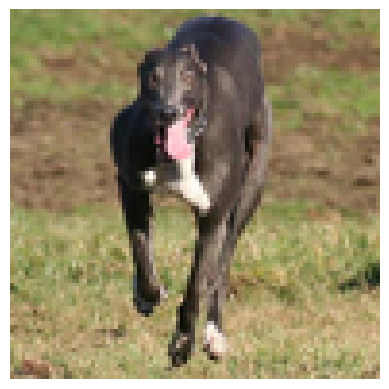

In [517]:
#a dataset sample
import matplotlib.pyplot as plt

image, label = train_ds[1]   # image shape: (C, H, W)

plt.imshow(image.permute(1, 2, 0))  # convert to (H, W, C)
plt.axis("off")
plt.show()

In [518]:
print('num-batches:', len(iter(train_dataloader)), '| batch-shape:', next(iter(train_dataloader))[0].shape)

num-batches: 1640 | batch-shape: torch.Size([64, 3, 96, 96])


In [519]:
def apply_2d_rope(q, k, n_latent_tokens, rope):
    assert q.shape == k.shape, 'q and k shapes must match'

    B, H, T, D = q.shape

    assert D % 4 == 0, 'head size must be divisible by 4'

    row_cos, row_sin, col_cos, col_sin = rope
    n_patches = row_cos.shape[0]

    assert T == n_latent_tokens + n_patches

    #match mixed-precision q/k
    row_cos = row_cos.to(dtype=q.dtype)
    row_sin = row_sin.to(dtype=q.dtype)
    col_cos = col_cos.to(dtype=q.dtype)
    col_sin = col_sin.to(dtype=q.dtype)

    def rotate_pairs(x, cos, sin):
        # (B, H, P, D/2)
        x = x.reshape(B, H, n_patches, D//4, 2)

        a, b = x.unbind(dim=-1)

        a_rot = a*cos - b*sin
        b_rot = a*sin + b*cos

        return torch.stack((a_rot, b_rot), dim=-1).flatten(-2)

    def rotate_tensor(x):
        original_T = x.shape[2]

        #latent tokens remain untouched
        x_latent = x[:, :, :n_latent_tokens]
        x_patch = x[:, :, n_latent_tokens:]

        assert x_latent.shape[2] == n_latent_tokens
        assert x_patch.shape[2] == n_patches

        #first half of channels use row position
        #second half of channesl use col position
        x_row, x_col = x_patch.chunk(2,dim=-1)

        x_row = rotate_pairs(x_row, row_cos, row_sin)
        x_col = rotate_pairs(x_col, col_cos, col_sin)

        x_patch = torch.cat((x_row, x_col), dim=-1) #pair up the row and col tokens along D

        x = torch.cat((x_latent, x_patch), dim=2) #stack latent and patch tokens along T
        assert x.shape[2] == original_T, (
            f"RoPE changed token count: {original_T} -> {x.shape[2]}"
        )

        return x

    return rotate_tensor(q), rotate_tensor(k)

In [520]:
#pre-norm multi-head attention
class MHA(nn.Module):
    def __init__(self, 
                 n_heads, 
                 head_size, 
                 emb_dim, 
                 n_latent_tokens
                ):
        super().__init__()

        self.n_heads = n_heads
        self.head_size = head_size
        self.emb_dim = emb_dim
        self.n_latent_tokens = n_latent_tokens

        self.norm = nn.LayerNorm(emb_dim)
        self.QKV = nn.Linear(emb_dim, 3*n_heads * head_size)

        self.out_proj = nn.Linear(n_heads * head_size, emb_dim)

        self.gamma = nn.Parameter(torch.full( (emb_dim,), layer_scale_gamma))

    def forward(self, x, rope):
        residual = x
        
        
        #useful for shape viewing/permuting below
        B, T, C = x.shape
        nh = self.n_heads
        hs = self.head_size

        #normalize
        x = self.norm(x)
        
        qkv = self.QKV(x) # (B, T, C) -> ( B, T, 3 * n_heads *head_size )

        #slice qkv aprt
        q = qkv[:, :, : nh * hs ] # ( B, T, n_heads * head_size )
        k = qkv[:, :, nh * hs : 2 * nh * hs ] # ( B, T, n_heads * head_size )
        v = qkv[:, :, 2 * nh * hs :] # ( B, T, n_heads * head_size )


        
        #reshape (B, T, n_heads*headsize) -> (B, n_heads, T, headsize)
        q = q.view(B, T, nh, hs).permute(0, 2, 1, 3)
        k = k.view(B, T, nh, hs).permute(0, 2, 1, 3)
        v = v.view(B, T, nh, hs).permute(0, 2, 1, 3)

        q, k = apply_2d_rope(
            q,
            k,
            n_latent_tokens=self.n_latent_tokens,
            rope=rope,
        )

        #q @ k.t / head_size **0.5
        out = F.scaled_dot_product_attention(
            q,
            k,
            v,
            dropout_p=0.0,
            is_causal=False,
        )

        out = out.permute(0, 2, 1, 3).flatten(-2) # (B, T, H*hs)

        out = residual + self.gamma * self.out_proj(out) # (B T C)


        return out
        

In [521]:
class MLP(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()

        self.gamma = nn.Parameter(torch.full((emb_dim,), layer_scale_gamma))
        
        self.net = nn.Sequential(
            nn.LayerNorm(emb_dim),
            nn.Linear(emb_dim, emb_dim*4),
            nn.GELU(),
            nn.Linear(emb_dim*4, emb_dim)
        )

    def forward(self, x):
        return x + self.gamma * self.net(x)

In [522]:
#transformer+MLP block
class Block(nn.Module):
    def __init__(self, 
                 n_heads, 
                 head_size, 
                 emb_dim,
                 n_latent_tokens):
        super().__init__()

        self.MHA = MHA(n_heads, head_size, emb_dim, n_latent_tokens)
        self.MLP = MLP(emb_dim)

    def forward(self, x, rope):

        x = self.MHA(x, rope)
        
        x = self.MLP(x)

        return x
        

In [523]:
class PatchEmbed(nn.Module):
    def __init__(self, patch_size, c, emb_dim):
        super().__init__()

        self.patch_size = patch_size

        self.embed = nn.Conv2d(in_channels = c,
                             out_channels = emb_dim,
                             kernel_size = patch_size,
                             stride = patch_size,
                             padding=0)


    def forward(self, x):
        B, C, H, W = x.shape
        patch_rows = H//patch_size
        patch_cols = W//patch_size

        
        out = self.embed(x) # (B, C, H, W) -> (B, emb_dim, pr, pc)
        out = out.flatten(-2).permute(0, 2, 1) # (B, T, C)

        return out, patch_rows, patch_cols

In [524]:
class PatchUnEmbed(nn.Module):
    def __init__(self, patch_size, c, emb_dim):
        super().__init__()

        self.patch_size = patch_size
        self.c = c
        self.emb_dim = emb_dim

        self.to_pixels = nn.Linear(emb_dim, c * patch_size**2)

    def forward(self, x, patch_rows, patch_cols):
        B, T, C = x.shape
        p = self.patch_size
        c = self.c

        x = self.to_pixels(x) # BTC -> B, T, c*p**2

        # Split token position and patch contents
        # (B, pr, pc, c, patch, patch)

        x = x.reshape(B,  patch_rows, patch_cols, c, p, p)

        # Interleave patch-grid and within-patch coordinates
        # (B, c, pr, patch, pc, patch)
        x = x.permute(0, 3, 1, 4, 2, 5)

        # Join them into image height and width
        # (B, c, pr*p, pc*p) 
        out = x.reshape(B, c, patch_rows*p, patch_cols*p)

        return out




In [525]:
#define core transformer model 

class CoreTransformer(nn.Module):
    def __init__(self, 
                 emb_dim, 
                 num_blocks, 
                 n_heads, 
                 head_size, 
                 n_latent_tokens
                ):
        
        super().__init__()

        self.n_latent_tokens = n_latent_tokens

        self.blocks = nn.ModuleList([
            Block(n_heads, head_size, emb_dim, n_latent_tokens)
                for _ in range(num_blocks)
        ])
        
        self.norm = nn.LayerNorm(emb_dim)

        #ROPE BUFFER
        pair_idx = torch.arange(head_size//4, dtype=torch.float32)
        inv_freq = 10_000 ** (-pair_idx / (head_size)//4)

        self.register_buffer("inv_freq", inv_freq, persistent=False)
        self.register_buffer("row_sin_cache", torch.empty(0), persistent=False)
        self.register_buffer("row_cos_cache", torch.empty(0), persistent=False)
        self.register_buffer("col_sin_cache", torch.empty(0), persistent=False)
        self.register_buffer("col_cos_cache", torch.empty(0), persistent=False)

        self.rope_cache_grid = None

    def forward(self, x, patch_rows, patch_cols):
        rope = self.get_rope_cache(patch_rows, patch_cols)
        
        for block in self.blocks:
            x = block(x, rope)

        x = self.norm(x)
    
        return x

    def get_rope_cache(self, patch_rows, patch_cols):
        grid = (patch_rows, patch_cols) #current layout

        if self.rope_cache_grid != grid: #only rebuild when the grid changes
            row_pos = torch.arange(
                patch_rows,
                device = self.inv_freq.device,
            ).repeat_interleave(patch_cols) # rpt interleaved makes pattern e.g. 000111222333 - 000N X cols - 1234...N up to rows

            
            col_pos = torch.arange(
                patch_cols,
                device=self.inv_freq.device,
            ).repeat(patch_rows) # rpt (no interleave) makes pattern e.g. 012301230123 - 0123.0123 X rows - 1234...N up to cols
    
            row_angles = row_pos[:, None] * self.inv_freq[None, :] 
            col_angles = col_pos[:, None] * self.inv_freq[None, :]
    
            self.row_cos_cache = row_angles.cos()
            self.row_sin_cache = row_angles.sin()
            self.col_cos_cache = col_angles.cos()
            self.col_sin_cache = col_angles.sin()
    
            self.rope_cache_grid = grid
        return (
            self.row_cos_cache,
            self.row_sin_cache,
            self.col_cos_cache,
            self.col_sin_cache,
        )

In [526]:
#define encoder model 
    
class Encoder(nn.Module):
    def __init__(self, 
                 patch_size, 
                 in_channels, 
                 ae_emb_dim,
                 emb_dim, 
                 n_ae_latent_tokens,
                 n_latent_tokens,
                 num_blocks, 
                 n_heads, 
                 head_size, 
                ):
        
        super().__init__()


        self.ae_emb_dim = ae_emb_dim
        self.emb_dim = emb_dim

        self.n_latent_tokens = n_latent_tokens
        self.n_ae_latent_tokens = n_ae_latent_tokens

        self.latent_tokens = nn.Parameter(torch.randn((1, n_ae_latent_tokens, ae_emb_dim)))

        self.mask_token = nn.Parameter(torch.randn((1, 1, ae_emb_dim)))

        self.embed = PatchEmbed(patch_size, in_channels, ae_emb_dim)

        self.core_transformer = CoreTransformer(emb_dim = ae_emb_dim, 
                                                 num_blocks = num_blocks, 
                                                 n_heads = n_heads, 
                                                 head_size = head_size, 
                                                 n_latent_tokens = n_ae_latent_tokens
                                                )

        self.out_norm = nn.LayerNorm(ae_emb_dim)
        self.token_out_proj = nn.Linear(n_ae_latent_tokens, n_latent_tokens, bias=False)
        self.emb_out_proj = nn.Linear(ae_emb_dim, emb_dim, bias=False)
        
    def forward(self, image, mask=None):
        
        patches, patch_rows, patch_cols = self.embed(image)

        if mask is not None:
            #mask patches
            #mask (B, T)
            #mask token (1, 1, C)
            #patches (B, T, C)
            patches = torch.where(
                mask.unsqueeze(-1),
                self.mask_token,
                patches,
            )
        
        # cat latent tokens with patch embed
        B = patches.shape[0]
        
        latents = self.latent_tokens.expand(B, -1, -1)
        x = torch.cat([latents, patches], dim=1)
        
        x = self.core_transformer(x, patch_rows, patch_cols)

        #slice latent tokens out of x
        latents = x[:, :self.n_ae_latent_tokens]

        patches = x[:, self.n_ae_latent_tokens:]

        latents = self.out_norm(latents)

        # out projection BTC -> BCT -> BTC
        latents = self.token_out_proj(latents.transpose(1,2)).transpose(1,2)
        z = self.emb_out_proj(latents)

        return z

In [527]:
# define decoder model

class Decoder(nn.Module):
    def __init__(
        self,
        patch_size,
        out_channels,
        ae_emb_dim,
        emb_dim,
        n_ae_latent_tokens,
        n_latent_tokens,
        num_blocks,
        n_heads,
        head_size,
    ):
        super().__init__()

        self.ae_emb_dim = ae_emb_dim
        self.emb_dim = emb_dim

        self.n_ae_latent_tokens = n_ae_latent_tokens
        self.n_latent_tokens = n_latent_tokens

        self.latent_slots = nn.Parameter(
            torch.randn(1, n_ae_latent_tokens, ae_emb_dim) * 0.02
        )

        self.emb_in_proj = nn.Linear(
            emb_dim,
            ae_emb_dim,
            bias=False,
        )

        self.token_in_proj = nn.Linear(
            n_latent_tokens,
            n_ae_latent_tokens,
            bias=False,
        )

        self.learned_patch_token = nn.Parameter(
            torch.randn(1, 1, ae_emb_dim)
        )

        self.core_transformer = CoreTransformer(
            emb_dim=ae_emb_dim,
            num_blocks=num_blocks,
            n_heads=n_heads,
            head_size=head_size,
            n_latent_tokens=n_ae_latent_tokens,
        )

        self.un_embed = PatchUnEmbed(
            patch_size=patch_size,
            c=out_channels,
            emb_dim=ae_emb_dim,
        )

        self.in_norm = nn.LayerNorm(ae_emb_dim)
        self.out_norm = nn.LayerNorm(ae_emb_dim)
        
    def forward(self, z):
    
        latents = self.emb_in_proj(z)
    
        latents = self.token_in_proj(
            latents.transpose(1, 2)
        ).transpose(1, 2)
        
        latents = latents + self.latent_slots
    
        B = latents.shape[0]
    
        patches = self.learned_patch_token.expand(
            B,
            patch_rows * patch_cols,
            -1,
        )

        x = torch.cat([latents, patches], dim=1)

        x = self.in_norm(x)
        
        x = self.core_transformer(
            x,
            patch_rows,
            patch_cols,
        )

        x = self.out_norm(x)

        patch_embeddings = x[:, self.n_ae_latent_tokens:]

        images = torch.sigmoid(
            self.un_embed(
                patch_embeddings,
                patch_rows,
                patch_cols,
            )
        )

        return images

        

In [528]:
def sliced_wasserstein_distance(
    z,
    prior,
    n_slices=32,
    bulk_sigma=1.0,       # smaller = stronger tail discount; None = unweighted
):
    assert z.shape == prior.shape
    if bulk_sigma is not None and bulk_sigma <= 0:
        raise ValueError("bulk_sigma must be positive or None")

    z = z.flatten(1)                         # (B, D)
    prior = prior.detach().flatten(1)        # fixed target
    B, D = z.shape

    slices = F.normalize(
        torch.randn(D, n_slices, device=z.device, dtype=z.dtype),
        dim=0,
    )                                       # (D, S)

    z_slices = torch.sort(z @ slices, dim=0).values.float()
    p_slices = torch.sort(prior @ slices, dim=0).values.float()

    squared_error = (z_slices - p_slices).square()

    if bulk_sigma is None:
        loss = squared_error.mean()
    else:
        log_weights = -0.5 * (p_slices / bulk_sigma).square()

        # Normalize across batch ranks, separately for each slice.
        # Softmax stably computes exp(log_weights) / sum(exp(log_weights)).
        weights = torch.softmax(log_weights, dim=0)

        loss = (weights * squared_error).sum(dim=0).mean()

    # Square the aggregate loss to damp pressure at low mismatch.
    return loss.square()

In [529]:
def basis_wasserstein_distance(z, prior, bulk_sigma=1.0):
    assert z.shape == prior.shape
    assert z.ndim == 3, "Expected z shaped (B, T, C)"

    if bulk_sigma is not None and bulk_sigma <= 0:
        raise ValueError("bulk_sigma must be positive or None")

    prior = prior.detach()

    def axis_loss(source, target, dim):
        source = torch.sort(source, dim=dim).values.float()
        target = torch.sort(target, dim=dim).values.float()

        squared_error = (source - target).square()

        if bulk_sigma is None:
            return squared_error.mean()

        log_weights = -0.5 * (target / bulk_sigma).square()
        weights = torch.softmax(log_weights, dim=dim)

        return (weights * squared_error).sum(dim=dim).mean()

    loss_b = axis_loss(z, prior, dim=0)   # across images, per (t, c)
    loss_t = axis_loss(z, prior, dim=1)   # across tokens, per (b, c)
    loss_c = axis_loss(z, prior, dim=2)   # across channels, per (b, t)
    loss_e = axis_loss(
        z.flatten(1), prior.flatten(1), dim=1
    )                                    # across T*C, per image

    loss = loss_b # + 0.1 * (loss_t + loss_c + loss_e) / 3
    
    # Square the aggregate loss to damp pressure at low mismatch.
    return  loss.square()

In [530]:
def token_sliced_wasserstein_distance(
    z,
    prior,
    n_slices=32,
    bulk_sigma=1.0,
):
    """
    Token-space SWD.

    z/prior: (B, T, C)

    Reshapes to (B*C, T), so each channel across the token sequence
    is one sample, and random slices operate across the T token dimensions.

    This directly pressures token combinations/correlations
    toward the isotropic Gaussian prior.
    """
    assert z.shape == prior.shape
    assert z.ndim == 3, "Expected z shaped (B, T, C)"

    if bulk_sigma is not None and bulk_sigma <= 0:
        raise ValueError("bulk_sigma must be positive or None")

    B, T, C = z.shape

    # Each channel's values across T tokens becomes one T-dimensional observation.
    z = z.permute(0, 2, 1).reshape(B * C, T)
    prior = prior.detach().permute(0, 2, 1).reshape(B * C, T)

    # Random directions through token space.
    slices = F.normalize(
        torch.randn(
            T,
            n_slices,
            device=z.device,
            dtype=z.dtype,
        ),
        dim=0,
    )  # (T, S)

    # Project each observation onto random token-space directions.
    z_slices = torch.sort(
        z @ slices,
        dim=0,
    ).values.float()

    p_slices = torch.sort(
        prior @ slices,
        dim=0,
    ).values.float()

    squared_error = (z_slices - p_slices).square()

    if bulk_sigma is None:
        loss = squared_error.mean()

    else:
        log_weights = -0.5 * (p_slices / bulk_sigma).square()

        # Normalize across the B*C observations for each slice.
        weights = torch.softmax(
            log_weights,
            dim=0,
        )

        loss = (
            weights * squared_error
        ).sum(dim=0).mean()

    return loss.square()

In [531]:
def channel_sliced_wasserstein_distance(
    z,
    prior,
    n_slices=32,
    bulk_sigma=1.0,
):
    """
    Channel-space SWD.

    z/prior: (B, T, C)

    Reshapes to (B*T, C), so each token embedding is one sample
    and random slices operate across the C channel dimensions.

    This directly pressures channel combinations/correlations
    toward the isotropic Gaussian prior.
    """
    assert z.shape == prior.shape
    assert z.ndim == 3, "Expected z shaped (B, T, C)"

    if bulk_sigma is not None and bulk_sigma <= 0:
        raise ValueError("bulk_sigma must be positive or None")

    B, T, C = z.shape

    # Each token embedding becomes one C-dimensional observation.
    z = z.reshape(B * T, C)
    prior = prior.detach().reshape(B * T, C)

    # Random directions through channel space.
    slices = F.normalize(
        torch.randn(
            C,
            n_slices,
            device=z.device,
            dtype=z.dtype,
        ),
        dim=0,
    )  # (C, S)

    # Project each token embedding onto each random channel direction.
    z_slices = torch.sort(
        z @ slices,
        dim=0,
    ).values.float()

    p_slices = torch.sort(
        prior @ slices,
        dim=0,
    ).values.float()

    squared_error = (z_slices - p_slices).square()

    if bulk_sigma is None:
        loss = squared_error.mean()

    else:
        log_weights = -0.5 * (p_slices / bulk_sigma).square()

        # Normalize across the B*T observations for each slice.
        weights = torch.softmax(
            log_weights,
            dim=0,
        )

        loss = (
            weights * squared_error
        ).sum(dim=0).mean()

    # Same low-mismatch damping behavior as your other Wasserstein losses.
    return loss.square()

In [532]:
def laplacian(x):
    C = x.shape[1]

    kernel = torch.tensor(
        [[0, -1,  0],
         [-1, 4, -1],
         [0, -1,  0]],
        device=x.device,
        dtype=x.dtype,
    )

    kernel = kernel[None, None].repeat(C, 1, 1, 1)

    return F.conv2d(x, kernel, padding=1, groups=C)

In [533]:
# helper: render reconstruction
@torch.no_grad()
def render_reconstruction(
    masked=False,
    show=True,
):
    features, _ = next(iter(test_dataloader))
    features = features[:8].to(device)

    if masked:
        mask = make_mask(features)

        z = encoder(
            features,
            mask,
        )

        pixel_mask = make_pixel_mask(
            mask,
            features,
        )

        display_features = (
            features * (1.0 - pixel_mask)
        )

    else:
        z = encoder(features)
        display_features = features

    x_hat = decoder(z)

    n = features.shape[0]

    fig, axes = plt.subplots(
        2,
        n,
        figsize=(2 * n, 4),
    )

    for i in range(n):
        axes[0, i].imshow(
            display_features[i]
            .float()
            .cpu()
            .permute(1, 2, 0)
            .clamp(0, 1)
        )
        axes[0, i].axis("off")

        axes[1, i].imshow(
            x_hat[i]
            .float()
            .cpu()
            .permute(1, 2, 0)
            .clamp(0, 1)
        )
        axes[1, i].axis("off")

    axes[0, 0].set_ylabel(
        "masked input" if masked else "input",
        rotation=0,
        labelpad=45,
        va="center",
    )

    axes[1, 0].set_ylabel(
        "recon",
        rotation=0,
        labelpad=35,
        va="center",
    )

    plt.tight_layout()

    if show:
        plt.show()
    else:
        plt.close(fig)

    return fig

In [534]:
#helper: def reconstruct images
@torch.no_grad()
def reconstruct_images(images, close_fig = False):
    
    x_hat = decoder(encoder(images))

    x = images[0].detach().cpu().permute(1, 2, 0)
    recon = x_hat[0].detach().cpu().permute(1, 2, 0)
    #recon = x_hat[0,0]

    fig, axs = plt.subplots(1, 2, figsize = (6,3))

    axs[0].imshow(x)
    axs[0].set_title('input')
    axs[0].axis('off')

    
    axs[1].imshow(recon)
    axs[1].set_title('reconstruction')
    axs[1].axis('off')

    if close_fig:
        plt.close(fig)

In [535]:
#helper: def plot_training_snapshot
import os
import torch
import matplotlib.pyplot as plt


@torch.no_grad()
def plot_training_snapshot(
    recon_targets,
    step,
    total_steps,
    save_path=None,
    show=False,
):
    """
    Plot four fixed reconstruction examples.

    Row 1: original targets
    Row 2: model reconstructions

    Assumes:
        recon_targets: (4, C, H, W)
        encoder and decoder exist in the outer scope
    """
    if recon_targets.ndim != 4:
        raise ValueError(
            f"Expected recon_targets shaped (4, C, H, W), "
            f"got {recon_targets.shape}"
        )

    if recon_targets.shape[0] != 4:
        raise ValueError(
            f"Expected exactly 4 reconstruction targets, "
            f"got {recon_targets.shape[0]}"
        )

    # Infer the model device rather than relying on a global `device`.
    model_device = next(encoder.parameters()).device
    targets = recon_targets.to(model_device)

    encoder_was_training = encoder.training
    decoder_was_training = decoder.training

    encoder.eval()
    decoder.eval()

    try:
        reconstructions = decoder(encoder(targets))
    finally:
        encoder.train(encoder_was_training)
        decoder.train(decoder_was_training)

    targets = targets.detach().float().cpu()
    reconstructions = reconstructions.detach().float().cpu()

    if reconstructions.shape != targets.shape:
        raise ValueError(
            "Target and reconstruction shapes do not match:\n"
            f"targets:         {targets.shape}\n"
            f"reconstructions: {reconstructions.shape}"
        )

    def prepare_for_imshow(image):
        """
        Convert:
            (1, H, W) -> (H, W)
            (3, H, W) -> (H, W, 3)
        """
        if image.ndim != 3:
            raise ValueError(
                f"Expected individual image shaped (C, H, W), got {image.shape}"
            )

        channels = image.shape[0]

        if channels == 1:
            return image.squeeze(0).clamp(0, 1).numpy()

        if channels in (3, 4):
            return image.permute(1, 2, 0).clamp(0, 1).numpy()

        raise ValueError(f"Cannot display image with {channels} channels")

    # Per-example reconstruction error for a compact progress signal.
    mse = (
        (targets - reconstructions)
        .square()
        .flatten(start_dim=1)
        .mean(dim=1)
    )

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(12, 6),
        gridspec_kw={
            "hspace": 0.08,
            "wspace": 0.08,
        },
    )

    fig.suptitle(
        f"Autoencoder Training — Step {step:,} / {total_steps:,}",
        fontsize=15,
        y=0.97,
    )

    for i in range(4):
        target = prepare_for_imshow(targets[i])
        reconstruction = prepare_for_imshow(reconstructions[i])

        # Top row: original
        axes[0, i].imshow(
            target,
            cmap="gray" if targets.shape[1] == 1 else None,
            vmin=0,
            vmax=1,
            interpolation="nearest",
        )
        axes[0, i].set_title(
            f"Sample {i + 1}\nMSE: {mse[i].item():.4f}",
            fontsize=10,
        )
        axes[0, i].axis("off")

        # Bottom row: reconstruction
        axes[1, i].imshow(
            reconstruction,
            cmap="gray" if reconstructions.shape[1] == 1 else None,
            vmin=0,
            vmax=1,
            interpolation="nearest",
        )
        axes[1, i].axis("off")

    # Shared row labels avoid repeating eight titles.
    fig.text(
        0.025,
        0.69,
        "Target",
        rotation=90,
        va="center",
        ha="center",
        fontsize=12,
    )
    fig.text(
        0.025,
        0.29,
        "Reconstruction",
        rotation=90,
        va="center",
        ha="center",
        fontsize=12,
    )

    fig.subplots_adjust(
        top=0.86,
        bottom=0.04,
        left=0.06,
        right=0.99,
    )

    if save_path is not None:
        save_dir = os.path.dirname(save_path)

        if save_dir:
            os.makedirs(save_dir, exist_ok=True)

        fig.savefig(
            save_path,
            dpi=120,
            bbox_inches="tight",
        )

    if show:
        plt.show()

    plt.close(fig)

In [536]:
# get split losses

@torch.inference_mode()
def get_split_loss(split):
    encoder_was_training = encoder.training
    decoder_was_training = decoder.training

    encoder.eval()
    decoder.eval()

    if split == "test":
        dataloader = test_dataloader
        max_batches = None

    elif split == "train":
        dataloader = train_dataloader
        max_batches = 20

    else:
        raise ValueError(f"Unknown split: {split}")

    masked_squared_error = torch.zeros((), device=device)
    clean_squared_error = torch.zeros((), device=device)
    num_elements = 0

    try:
        for batch_index, (x, _) in enumerate(dataloader):
            if max_batches is not None and batch_index >= max_batches:
                break

            x = x.to(device)

            x_hat_masked = decoder(
                encoder(x, make_mask(x))
            )

            masked_squared_error += F.mse_loss(
                x_hat_masked,
                x,
                reduction="sum",
            )

            x_hat_clean = decoder(
                encoder(x)
            )

            clean_squared_error += F.mse_loss(
                x_hat_clean,
                x,
                reduction="sum",
            )

            num_elements += x.numel()

    finally:
        encoder.train(encoder_was_training)
        decoder.train(decoder_was_training)

    loss_masked = masked_squared_error / num_elements
    loss_clean = clean_squared_error / num_elements

    return loss_masked, loss_clean

In [537]:
#log metrics
from collections import defaultdict
from copy import deepcopy

if "logs" not in globals():
    logs = defaultdict(list)


def clear_logs():
    logs.clear()


def log_metrics(**metrics):
    for name, value in metrics.items():
        if value is None:
            continue

        if torch.is_tensor(value):
            value = value.detach().item()

        logs[name].append(value)


def get_metrics():
    return {
        name: history[-1]
        for name, history in logs.items()
        if history
    }

def get_metrics_lists():
    return {
        name: history.copy()
        for name, history in logs.items()
        if history
    }

In [538]:
## plot decoded images from list of seeds
@torch.no_grad()
def plot_constructions(seeds, patch_rows=None, patch_cols=None):

    constructs = decode_z(
        seeds.to(device),
        patch_rows,
        patch_cols,
    ).cpu()

    n = constructs.shape[0]

    fig, axes = plt.subplots(1, n, figsize=(n * 2, 4))

    if n == 1:
        axes = [axes]

    for i, ax in enumerate(axes):
        img = constructs[i].permute(1, 2, 0).float().clamp(0, 1)
        ax.imshow(img)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [539]:
# plot objective losses
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


def moving_average(values, window=100):
    values = np.asarray(values)
    return np.convolve(
        values,
        np.ones(window) / window,
        mode="valid",
    )


def plot_objective_losses(
    window=1000,
    start=0,
    end=None,
    show=True,
):
    history = get_metrics_lists()

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(
        moving_average(history["clean_term"], window)[start:end],
        label="clean recon",
    )
    
    # ax.plot(
    #     moving_average(history["view_term"], window)[start:end],
    #     label="view invariance",
    # )

    ax.plot(
        moving_average(history["laplacian_term"], window)[start:end],
        label="Laplacian",
    )

    # ax.plot(
    #     moving_average(history["masked_term"], window)[start:end],
    #     label="masked prediction",
    # )

    ax.xaxis.set_major_formatter(
        FuncFormatter(
            lambda x, _: (
                f"start\n({start:,})"
                if abs(x) < 1
                else f"+{x/1000:.0f}k"
            )
        )
    )

    ax.set_xlabel("Training step")
    ax.set_ylabel("Smoothed loss")
    ax.set_title(
        f"objective losses — {window}-step moving average"
    )

    ax.legend()
    ax.grid(alpha=0.3)

    if show:
        plt.show()

    return fig

In [540]:
def plot_regularization_losses(
    window=1000,
    start=0,
    end=None,
    show=True,
):
    history = get_metrics_lists()

    fig, ax = plt.subplots(figsize=(10, 5))


    ax.plot(
        moving_average(history["swd_term"], window)[start:end],
        label="SWD",
    )
    ax.plot(
        moving_average(history["bwd_term"], window)[start:end],
        label="BWD",
    )
    ax.plot(
        moving_average(history["c_swd_term"], window)[start:end],
        label="C_SWD",
    )
    ax.plot(
        moving_average(history["t_swd_term"], window)[start:end],
        label="T_SWD",
    )

    ax.xaxis.set_major_formatter(
        FuncFormatter(
            lambda x, _: (
                f"start\n({start:,})"
                if abs(x) < 1
                else f"+{x/1000:.0f}k"
            )
        )
    )

    ax.set_xlabel("Training step")
    ax.set_ylabel("Smoothed loss")
    ax.set_title(
        f"regularization losses — {window}-step moving average"
    )

    ax.legend()
    ax.grid(alpha=0.3)

    if show:
        plt.show()

    return fig

In [559]:
def save_reconstruction_snapshot(masked=False):
    fig = render_reconstruction(
        masked=masked,
        show=False,
    )

    filename = (
        "latest_recon_masked.png"
        if masked
        else "latest_recon_clean.png"
    )

    fig.savefig(
        preview_dir / filename,
        dpi=130,
        bbox_inches="tight",
    )

    plt.close(fig)

In [542]:
def save_loss_snapshots(
    window_full=1000,
    window_recent=200,
    recent_steps=20_000,
):
    history = get_metrics_lists()
    n_steps = len(history["clean_term"])

    fig = plot_objective_losses(
        window=window_full,
        start=0,
        show=False,
    )
    fig.savefig(
        preview_dir / "latest_objective_full.png",
        dpi=130,
        bbox_inches="tight",
    )
    plt.close(fig)

    fig = plot_regularization_losses(
        window=window_full,
        start=0,
        show=False,
    )
    fig.savefig(
        preview_dir / "latest_regularization_full.png",
        dpi=130,
        bbox_inches="tight",
    )
    plt.close(fig)

    recent_start = max(0, n_steps - recent_steps)

    fig = plot_objective_losses(
        window=window_recent,
        start=recent_start,
        show=False,
    )
    fig.savefig(
        preview_dir / "latest_objective_recent.png",
        dpi=130,
        bbox_inches="tight",
    )
    plt.close(fig)

    fig = plot_regularization_losses(
        window=window_recent,
        start=recent_start,
        show=False,
    )
    fig.savefig(
        preview_dir / "latest_regularization_recent.png",
        dpi=130,
        bbox_inches="tight",
    )
    plt.close(fig)

In [543]:
#Helper: MULTIVIEW EVALUATION ##

@torch.no_grad()
def evaluate_multiview(max_batches=20, seed=1234):
    encoder_was_training = encoder.training
    decoder_was_training = decoder.training

    encoder.eval()
    decoder.eval()

    eval_device = next(encoder.parameters()).device
    cuda_devices = (
        [eval_device.index if eval_device.index is not None
         else torch.cuda.current_device()]
        if eval_device.type == "cuda" else []
    )

    def evaluate_split(loader):
        clean_sum = 0.0
        clean_count = 0
        masked_sum = 0.0
        masked_count = 0

        for batch_index, (images, _) in enumerate(loader):
            if max_batches is not None and batch_index >= max_batches:
                break

            images = images.to(device)
            B, channels, H, W = images.shape
            assert H % pr == 0 and W % pc == 0

            mask = make_mask(images)
            clean_mask = torch.zeros_like(mask)

            pixel_mask = (
                mask.reshape(B, 1, pr, pc)
                .repeat_interleave(H // pr, dim=2)
                .repeat_interleave(W // pc, dim=3)
            ).to(images.dtype)

            clean = decoder(encoder(images, clean_mask))
            masked = decoder(encoder(images, mask))

            clean_sum += F.mse_loss(
                clean, images, reduction="sum"
            ).item()
            clean_count += images.numel()

            masked_errors = F.mse_loss(
                masked, images, reduction="none"
            )
            masked_sum += (masked_errors * pixel_mask).sum().item()
            masked_count += pixel_mask.sum().item() * channels

        if clean_count == 0 or masked_count == 0:
            raise ValueError("Evaluation needs images and at least one masked pixel.")

        return clean_sum / clean_count, masked_sum / masked_count

    try:
        with torch.random.fork_rng(devices=cuda_devices):
            torch.random.default_generator.manual_seed(seed)
            if cuda_devices:
                with torch.cuda.device(cuda_devices[0]):
                    torch.cuda.manual_seed(seed)

            test_clean, test_missing = evaluate_split(test_dataloader)
            train_clean, train_missing = evaluate_split(train_dataloader)
    finally:
        encoder.train(encoder_was_training)
        decoder.train(decoder_was_training)

    return {
        "test clean": test_clean,
        "train clean": train_clean,
        "test missing": test_missing,
        "train missing": train_missing,
    }

In [544]:
from copy import deepcopy
from pathlib import Path
from datetime import datetime
import torch

RUN_DIR = Path("training_runs")
CHECKPOINT_DIR = Path("checkpoints")

RUN_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

runs = {}

def archive_current_run():
    if current_run_name is None:
        print("warning: current_run_name is None")
        return

    checkpoint_root = Path(os.environ["ML_CHECKPOINTS"])
    checkpoint_dir = checkpoint_root / "ae"
    run_dir = checkpoint_root.parent / "training_runs" / "ae"

    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    run_dir.mkdir(parents=True, exist_ok=True)

    history = deepcopy(get_metrics_lists())

    history_path = run_dir / f"{current_run_name}.pt"
    checkpoint_path = checkpoint_dir / f"{current_run_name}.pt"

    torch.save(
        {
            "encoder": encoder.state_dict(),
            "decoder": decoder.state_dict(),
        },
        checkpoint_path,
    )

    torch.save(
        {"history": history},
        history_path,
    )

    runs[current_run_name] = history

    print(
        f"archived {current_run_name}: "
        f"{len(history.get('recon_loss', [])):,} steps\n"
        f"History: {history_path}\n"
        f"Checkpoint: {checkpoint_path}"
    )


def start_run(name):
    global current_run_name

    archive_current_run()
    clear_logs()

    timestamp = datetime.now().strftime("%Y-%m-%d_%H%M%S")
    current_run_name = f"{timestamp}_{name}"

    print(f"started run: {current_run_name}")

In [545]:
def start_z_gradient_diagnostics(z, **weighted_regularizers):
    if not TRACK_Z_DIAGNOSTICS:
        return None

    z.retain_grad()

    gradients = {}
    for name, loss in weighted_regularizers.items():
        gradients[name] = torch.autograd.grad(
            loss,
            z,
            retain_graph=True,
        )[0].detach()

    # retain_grad() can capture gradients from the diagnostic passes.
    # Clear them so the real backward supplies only the total gradient.
    z.grad = None

    return gradients


def finish_z_gradient_diagnostics(enc, diagnostic):
    if diagnostic is None:
        return {}

    if z.grad is None:
        raise RuntimeError("Call finish diagnostics after ae_loss.backward().")

    with torch.no_grad():
        g_remaining = z.grad.detach().float().clone()

        for gradient in diagnostic.values():
            g_remaining.sub_(gradient.float())

        remaining_rms = g_remaining.square().mean().sqrt()

        metrics = {"remaining_grad_rms": remaining_rms}
        for name, gradient in diagnostic.items():
            rms = gradient.float().square().mean().sqrt()
            metrics[f"{name}_grad_rms"] = rms
            metrics[f"{name}_grad_ratio"] = rms / remaining_rms.clamp_min(1e-12)

    return metrics

In [546]:
def align_sigreg_grad(g_recon, g_sig, mode="plain", eps=1e-8):
    """
    Shape SIGReg's gradient relative to reconstruction.
    Projection is per image over the full latent [T, C].
    """
    shape = g_sig.shape

    gr = g_recon.flatten(1)
    gs = g_sig.flatten(1)

    # signed amount of SIGReg gradient parallel to recon gradient
    c = (
        (gs * gr).sum(dim=1, keepdim=True)
        / gr.square().sum(dim=1, keepdim=True).clamp_min(eps)
    )

    g_parallel = c * gr
    g_perp = gs - g_parallel

    if mode == "plain":
        out = gs

    elif mode == "sovereign":
        # SIGReg gets only directions locally neutral to recon
        out = g_perp

    elif mode == "protected":
        # remove only anti-recon parallel component
        out = gs - c.clamp(max=0) * gr

    elif mode == "reinforce":
        # keep only parallel component that helps recon
        out = c.clamp(min=0) * gr

    else:
        raise ValueError(f"unknown mode: {mode}")

    return out.view(shape)

In [547]:
# --------------------Def Init Models (and optimizers) --------------------


def init_models():
    
    encoder = Encoder(
        patch_size,
        c,
        ae_emb_dim,
        emb_dim,
        n_ae_latent_tokens,
        n_latent_tokens,
        num_blocks,
        n_heads,
        head_size,
    )
    
    decoder = Decoder(
        patch_size,
        c,
        ae_emb_dim,
        emb_dim,
        n_ae_latent_tokens,
        n_latent_tokens,
        num_blocks,
        n_heads,
        head_size,
    )
    
    
    device = "cuda" if torch.cuda.is_available() else "cpu"
    
    encoder.to(device)
    decoder.to(device)
    
    
    # -------------------- Optimizers --------------------
    
    ae_parameters = (
        list(encoder.parameters())
        + list(decoder.parameters())
    )
    n_ae_parameters  = sum(p.numel() for p in ae_parameters)
    print(f"{n_ae_parameters:,} ae parameters")
    
    ae_optimizer = torch.optim.AdamW(
        ae_parameters,
        lr=lr,
        fused=True,
    )

    return (
        encoder,
        decoder,
        ae_optimizer,
        device,
    )


In [548]:
import time
import torch


class TrainingReadout:
    def __init__(
        self,
        step_metrics,
        report_every=500,
        watch="test clean",
        trend_epochs=5,
    ):
        # Mapping: display label -> key returned by your training step.
        self.step_metrics = step_metrics
        self.report_every = report_every
        self.watch = watch
        self.trend_epochs = trend_epochs
        self.total_steps = 0
        self.history = []

    @staticmethod
    def _number(value):
        if torch.is_tensor(value):
            return value.detach().item()
        return float(value)

    @staticmethod
    def _gain(old, new):
        if old == 0:
            return "—"
        return f"{100 * (old - new) / abs(old):+.1f}%"

    def start(self, title, total_epochs, evaluation):
        self.total_epochs = total_epochs
        self.history = [
            {key: self._number(value) for key, value in evaluation.items()}
        ]
        self.total_steps = 0

        print(f"\n{title} | {total_epochs} epochs")
        print(
            "START | "
            + " | ".join(
                f"{key} {value:.5f}"
                for key, value in self.history[0].items()
            )
        )

    def begin_epoch(self, epoch, phase=""):
        self.epoch = epoch
        self.epoch_steps = 0
        self.epoch_samples = 0
        self.epoch_sums = {}

        self.interval_steps = 0
        self.interval_samples = 0
        self.interval_sums = {}

        print(f"\nE{epoch}/{self.total_epochs} {phase}".rstrip())
        print(
            f"{'STEP':>8}"
            + "".join(f" {label:>10}" for label in self.step_metrics)
            + f" {'ms/step':>9} {'img/s':>8}"
        )

        self.epoch_start = time.perf_counter()
        self.interval_start = self.epoch_start

    def update(self, metrics, batch_size, last_batch=False):
        self.total_steps += 1
        self.epoch_steps += 1
        self.interval_steps += 1
        self.epoch_samples += batch_size
        self.interval_samples += batch_size

        for key in self.step_metrics.values():
            value = metrics[key]
            if torch.is_tensor(value):
                value = value.detach()

            # Keep tensor sums on-device; convert only when reporting.
            contribution = value * batch_size
            self.epoch_sums[key] = self.epoch_sums.get(key, 0) + contribution
            self.interval_sums[key] = (
                self.interval_sums.get(key, 0) + contribution
            )

        if self.interval_steps >= self.report_every or last_batch:
            averages = {
                key: self._number(value / self.interval_samples)
                for key, value in self.interval_sums.items()
            }

            # Read scalar values before measuring elapsed time so GPU work
            # needed for these metrics has finished.
            now = time.perf_counter()
            elapsed = max(now - self.interval_start, 1e-9)
            self.train_seconds = now - self.epoch_start

            print(
                f"{self.total_steps:8d}"
                + "".join(
                    f" {averages[key]:10.5f}"
                    for key in self.step_metrics.values()
                )
                + f" {1000 * elapsed / self.interval_steps:9.0f}"
                + f" {self.interval_samples / elapsed:8.0f}"
            )

            self.interval_steps = 0
            self.interval_samples = 0
            self.interval_sums = {}
            self.interval_start = time.perf_counter()

    def end_epoch(self, evaluation):
        current = {
            key: self._number(value) for key, value in evaluation.items()
        }
        previous = self.history[-1]
        self.history.append(current)

        n = self.trend_epochs
        older = self.history[-n - 1] if len(self.history) > n else None

        best_index = min(
            range(len(self.history)),
            key=lambda i: self.history[i][self.watch],
        )
        best = self.history[best_index][self.watch]
        best_at = "start" if best_index == 0 else f"E{best_index}"

        value = current[self.watch]
        gain_1 = self._gain(previous[self.watch], value)
        gain_n = self._gain(older[self.watch], value) if older else "—"

        print(
            f"\nE{self.epoch}/{self.total_epochs}"
            f" | {self.watch} {value:.5f}"
            f" | gain {gain_1}/1ep {gain_n}/{n}ep"
            f" | best {best:.5f} @{best_at}"
            f" | {self.train_seconds / 60:.2f} min"
        )
        print(
            "Other eval | "
            + " | ".join(
                f"{key} {value:.5f}"
                for key, value in current.items()
                if key != self.watch
            )
        )

In [549]:
# current_run_name = "ae_5M_jepa_recon_no_dec_latent_slots"

# archive_current_run()

In [491]:
######################################################################################################################################
############################################################ init models #############################################################
######################################################################################################################################


SEED = 42

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
train_generator.manual_seed(DATA_SEED)

(
    encoder,
    decoder,
    ae_optimizer,
    device,
) = init_models()
torch._functorch.config.donated_buffer = not TRACK_Z_DIAGNOSTICS

1,003,408 ae parameters


In [492]:
start_run(current_run_name)

archived ae_1M_jepa_recon_only_lr5e-4_norms: 0 steps
History: <home>/projects/Jupyter_AI/training_runs/ae/ae_1M_jepa_recon_only_lr5e-4_norms.pt
Checkpoint: <home>/projects/Jupyter_AI/checkpoints/ae/ae_1M_jepa_recon_only_lr5e-4_norms.pt
started run: 2026-09-14_134955_ae_1M_jepa_recon_only_lr5e-4_norms


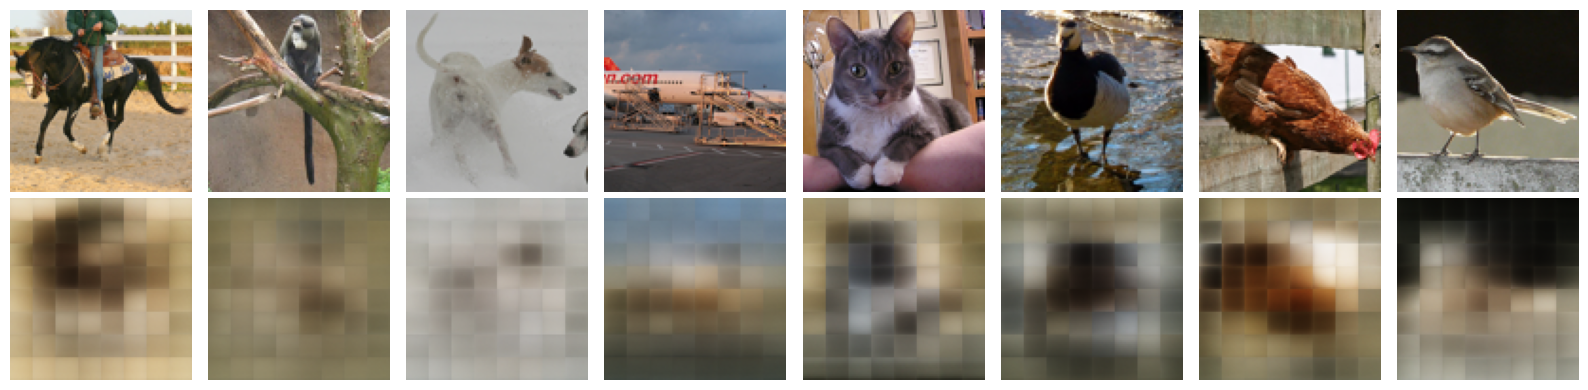

In [560]:
render_reconstruction(); #test model recon

In [551]:
################## Training Step Methods ########################

def make_pixel_mask(mask, images):
    B, _, H, W = images.shape

    return (
        mask.reshape(B, 1, pr, pc)
        .repeat_interleave(H // pr, dim=2)
        .repeat_interleave(W // pc, dim=3)
        .to(images.dtype)
    )


def masked_mse(prediction, target, pixel_mask):
    errors = F.mse_loss(
        prediction,
        target,
        reduction="none",
    )

    missing_values = (
        pixel_mask.sum() * target.shape[1]
    ).clamp_min(1)

    return (errors * pixel_mask).sum() / missing_values


def make_mask(images, min_mask=0.4, max_mask=0.6):
    B = images.shape[0]
    T = pr * pc

    min_k = int(min_mask * T)
    max_k = int(max_mask * T)

    n_mask = torch.randint(
        min_k,
        max_k + 1,
        (),
        device=images.device,
    )

    mask_indices = torch.rand(
        B,
        T,
        device=images.device,
    ).topk(
        k=max_k,
        dim=1,
        largest=False,
    ).indices

    selected = (
        torch.arange(max_k, device=images.device)[None, :]
        < n_mask
    ).expand(B, -1)

    mask = torch.zeros(
        B,
        T,
        dtype=torch.bool,
        device=images.device,
    )

    mask.scatter_(
        dim=1,
        index=mask_indices,
        src=selected,
    )

    return mask


def make_train_step(
    use_masked_view=True,
    view_mode="symmetric",
):
    """
    use_masked_view:
        False -> pure reconstruction
        True  -> clean + masked reconstruction

    view_mode:
        "none"
            No latent view-alignment loss.

        "symmetric"
            Both clean and masked latents receive gradients:
            MSE(z_masked, z_clean)

        "clean_target"
            Clean latent is the stop-grad target:
            MSE(z_masked, z_clean.detach())

    These settings are fixed when the train step is created,
    which keeps the compiled graph static.
    """

    if view_mode not in {
        "none",
        "symmetric",
        "clean_target",
    }:
        raise ValueError(
            f"Unknown view_mode: {view_mode}"
        )

    if not use_masked_view and view_mode != "none":
        raise ValueError(
            "view_mode must be 'none' when use_masked_view=False"
        )

    def train_step(images, optimizer, view_weight):

        B = images.shape[0]

        optimizer.zero_grad(set_to_none=True)

        clean_mask = torch.zeros(
            B,
            pr * pc,
            dtype=torch.bool,
            device=images.device,
        )

        # --------------------------------
        # Masks
        # --------------------------------

        if use_masked_view:
            mask = make_mask(images)
            pixel_mask = make_pixel_mask(
                mask,
                images,
            )

        # --------------------------------
        # Forward
        # --------------------------------

        with torch.autocast(
            device_type="cuda",
            dtype=torch.bfloat16,
        ):
            z_clean = encoder(
                images,
                clean_mask,
            )
        
            recon_clean = decoder(
                z_clean,
            )
        
            if use_masked_view:
                z_masked = encoder(
                    images,
                    mask,
                )
        
                recon_masked = decoder(
                    z_masked,
                )
        
        z_clean = z_clean.float()
        recon_clean = recon_clean.float()
        
        if use_masked_view:
            z_masked = z_masked.float()
            recon_masked = recon_masked.float()

        # --------------------------------
        # Reconstruction
        # --------------------------------

        clean_recon = F.mse_loss(
            recon_clean,
            images,
        )

        if use_masked_view:
            masked_recon = masked_mse(
                recon_masked,
                images,
                pixel_mask,
            )

            clean_term = 0.5 * clean_recon
            masked_term = 0.5 * masked_recon

        else:
            clean_term = clean_recon
            masked_term = z_clean.new_zeros(())

        # --------------------------------
        # View alignment
        # --------------------------------

        if view_mode == "symmetric":
            view_term = view_weight * F.mse_loss(
                z_masked,
                z_clean,
            )

        elif view_mode == "clean_target":
            view_term = view_weight * F.mse_loss(
                z_masked,
                z_clean.detach(),
            )

        else:
            view_term = z_clean.new_zeros(())

        # --------------------------------
        # Laplacian
        # --------------------------------

        image_highfreq = laplacian(images)

        clean_laplacian = F.mse_loss(
            laplacian(recon_clean),
            image_highfreq,
        )

        if use_masked_view:
            masked_laplacian = masked_mse(
                laplacian(recon_masked),
                image_highfreq,
                pixel_mask,
            )

            laplacian_term = (
                0.5
                * laplacian_weight
                * (
                    clean_laplacian
                    + masked_laplacian
                )
            )

        else:
            masked_laplacian = z_clean.new_zeros(())

            laplacian_term = (
                laplacian_weight
                * clean_laplacian
            )

        # --------------------------------
        # Latent regularization
        # --------------------------------

        prior = torch.randn_like(z_clean)

        clean_swd = sliced_wasserstein_distance(
            z_clean,
            prior,
        )

        clean_bwd = basis_wasserstein_distance(
            z_clean,
            prior,
        )

        clean_c_swd = channel_sliced_wasserstein_distance(
            z_clean,
            prior,
        )

        clean_t_swd = token_sliced_wasserstein_distance(
            z_clean,
            prior,
        )

        if use_masked_view:
            masked_swd = sliced_wasserstein_distance(
                z_masked,
                prior,
            )

            masked_bwd = basis_wasserstein_distance(
                z_masked,
                prior,
            )

            masked_c_swd = channel_sliced_wasserstein_distance(
                z_masked,
                prior,
            )

            masked_t_swd = token_sliced_wasserstein_distance(
                z_masked,
                prior,
            )

            swd_term = (
                swd_weight
                * 0.5
                * (clean_swd + masked_swd)
            )

            bwd_term = (
                bwd_weight
                * 0.5
                * (clean_bwd + masked_bwd)
            )

            c_swd_term = (
                c_swd_weight
                * 0.5
                * (clean_c_swd + masked_c_swd)
            )

            t_swd_term = (
                t_swd_weight
                * 0.5
                * (clean_t_swd + masked_t_swd)
            )

        else:
            masked_swd = z_clean.new_zeros(())
            masked_bwd = z_clean.new_zeros(())
            masked_c_swd = z_clean.new_zeros(())
            masked_t_swd = z_clean.new_zeros(())

            swd_term = (
                swd_weight * clean_swd
            )

            bwd_term = (
                bwd_weight * clean_bwd
            )

            c_swd_term = (
                c_swd_weight * clean_c_swd
            )

            t_swd_term = (
                t_swd_weight * clean_t_swd
            )

        # --------------------------------
        # Total
        # --------------------------------

        ae_loss = (
            clean_term
            + masked_term
            + laplacian_term
            + view_term
            + swd_term
            + bwd_term
            + c_swd_term
            + t_swd_term
        )

        ae_loss.backward()
        optimizer.step()

        # --------------------------------
        # Metrics
        # --------------------------------

        return {
            "ae_loss": ae_loss.detach(),

            "clean_term": clean_term.detach(),
            "masked_term": masked_term.detach(),
            "laplacian_term": laplacian_term.detach(),
            "view_term": view_term.detach(),

            "swd_term": swd_term.detach(),
            "bwd_term": bwd_term.detach(),
            "c_swd_term": c_swd_term.detach(),
            "t_swd_term": t_swd_term.detach(),

            "clean_swd": clean_swd.detach(),
            "masked_swd": masked_swd.detach(),

            "clean_bwd": clean_bwd.detach(),
            "masked_bwd": masked_bwd.detach(),

            "clean_c_swd": clean_c_swd.detach(),
            "masked_c_swd": masked_c_swd.detach(),

            "clean_t_swd": clean_t_swd.detach(),
            "masked_t_swd": masked_t_swd.detach(),
        }

    return train_step


def train_step_refine_decoder(
    images,
    optimizer,
    noise_sigma,
):
    B = images.shape[0]

    optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.bfloat16,
    ):
        with torch.no_grad():
            z = encoder(images)

            noise_mask = (
                torch.rand(
                    (B, 1, 1),
                    device=images.device,
                ) < 0.5
            )

            z = z + (
                torch.randn_like(z)
                * noise_sigma
                * noise_mask
            )

        x_hat = decoder(z)

    x_hat = x_hat.float()

    recon_loss = F.mse_loss(
        x_hat,
        images,
    )

    recon_loss.backward()
    optimizer.step()

    return {
        "recon": recon_loss.detach(),
    }

In [561]:
#make and compile the training steps
train_step = make_train_step(
    use_masked_view=use_masked_view,
    view_mode=view_mode,
)

train_step = torch.compile(
    train_step,
)

In [562]:
# fixed_micro_batch_size = 6
# fixed_micro_batch = next(iter(train_dataloader))[0][:fixed_micro_batch_size].to(device)
# fixed_mask = make_mask(fixed_micro_batch)

In [563]:
# #OVERFIT MICRO-BATCH
# num_epochs = 10


# encoder.train()
# decoder.train()

# report_every = 500

# report_start = time.perf_counter()

# train_loss = get_split_loss('train')
# test_loss = get_split_loss('test')

# print(f'START TRAINING | recon-train-loss:{train_loss:.5f}  recon-test-loss: {test_loss:.5f}')

# for epoch in range(num_epochs): 
#     for batch_step, (images, _) in enumerate(train_dataloader):

#         total_steps = epoch*batches_per_epoch + batch_step

#         metrics = train_step_simple(fixed_micro_batch)

#         if ((total_steps+1) % report_every) == 0:

#             elapsed = time.perf_counter() - report_start
#             sec_per_step = elapsed / report_every
#             samples_per_sec = images.shape[0] / sec_per_step

#             report_start = time.perf_counter()

#             print(
#                 f"\nstep {total_steps + 1} | "
#                 f"{sec_per_step * 1000:.0f} ms/step | "
#                 f"{samples_per_sec:.1f} samples/s | "
#                 f"{len(train_dataloader) * sec_per_step / 60:.1f} min/epoch "

#                 f" --- GPU alloc={torch.cuda.memory_allocated()/1e9:.2f} GB | "
#                 f"reserved={torch.cuda.memory_reserved()/1e9:.2f} GB | "
#                 f"peak={torch.cuda.max_memory_allocated()/1e9:.2f} GB"
#             )
            
#             msg = (
#                 f"AE:"
#                 f" total={metrics['ae_loss']:.5f}"
#                 f" | recon={metrics['recon_loss']:.5f}"
#                 f" | swd={metrics['swd_loss']:.5f}"
#                 f" | bwd={metrics['bwd_loss']:.5f}"
#                 f" | laplacian={metrics['laplacian_loss']:.5f}"
#             )
            
#             if TRACK_Z_DIAGNOSTICS:
#                 msg += (
#                     f" | s/r-ratio={metrics['grad_ratio']:.5f}"
#                     f" | v/r-ratio={metrics['variance_ratio']:.5f}"
#                 )
                
#             print(msg)


#     #render_reconstruction()
#     train_loss = get_split_loss('train')
#     test_loss = get_split_loss('test')
#     print(' ')
#     print('--------------------------------------------------------------')
#     print(f'EPOCH:{epoch} | recon-train-loss:{train_loss:.5f}  recon-test-loss: {test_loss:.5f}')
#     print('--------------------------------------------------------------')


      

In [564]:
# for image in fixed_micro_batch:
#     reconstruct_images(image[None, ...])

In [565]:
from pathlib import Path

preview_dir = Path("training_runs") / current_run_name / "latest"
preview_dir.mkdir(parents=True, exist_ok=True)

print(preview_dir)

training_runs/ae_1M_jepa_recon_only_lr5e-4_norms/latest


In [ ]:
## AE EXPERIMENT TRAINING LOOP ##

num_epochs = 200-5
train_lr = lr
report_every = 500
eval_batches = 20  # None = full loaders

encoder.requires_grad_(True)
decoder.requires_grad_(True)

train_optimizer = ae_optimizer

for group in train_optimizer.param_groups:
    group["lr"] = train_lr

readout = TrainingReadout(
    step_metrics={
        "clean": "clean_term",
        "missing": "masked_term",
        "view": "view_term",
        "swd": "swd_term",
        "bwd": "bwd_term",
        "c_swd": "c_swd_term",
        "t_swd": "t_swd_term",
    },
    report_every=report_every,
    watch="test clean",
    trend_epochs=5,
)

readout.start(
    title=(
        f"{current_run_name} | "
        f"masked={use_masked_view} | "
        f"view={view_mode} | "
        f"view_weight={view_weight:g}"
    ),
    total_epochs=num_epochs,
    evaluation=evaluate_multiview(
        max_batches=eval_batches,
    ),
)

steps_per_epoch = len(train_dataloader)

for epoch in range(num_epochs):
    encoder.train()
    decoder.train()

    readout.begin_epoch(
        epoch + 1,
        phase="TRAIN",
    )

    for batch_step, (images, _) in enumerate(train_dataloader):
        images = images.to(
            device,
            non_blocking=True,
        )

        metrics = train_step(
            images,
            optimizer=train_optimizer,
            view_weight=view_weight,
        )

        log_metrics(**metrics)

        readout.update(
            metrics,
            batch_size=images.shape[0],
            last_batch=(batch_step + 1 == steps_per_epoch),
        )

    readout.end_epoch(
        evaluate_multiview(
            max_batches=eval_batches,
        )
    )
    save_loss_snapshots()
    save_reconstruction_snapshot(masked=False)
    save_reconstruction_snapshot(masked=True)

    plt.close("all")


ae_1M_jepa_recon_only_lr5e-4_norms | masked=False | view=none | view_weight=0.001 | 195 epochs
START | test clean 0.01876 | train clean 0.01866 | test missing 0.04172 | train missing 0.04185

E1/195 TRAIN
    STEP      clean    missing       view        swd        bwd      c_swd      t_swd   ms/step    img/s
     500    0.01879    0.00000    0.00000    0.00069    0.00045    0.00052    0.00008        15     4230
    1000    0.01832    0.00000    0.00000    0.00065    0.00043    0.00049    0.00008        15     4258
    1500    0.01790    0.00000    0.00000    0.00066    0.00043    0.00050    0.00007        15     4240
    1640    0.01794    0.00000    0.00000    0.00064    0.00043    0.00050    0.00007        15     4241

E1/195 | test clean 0.01762 | gain +6.1%/1ep —/5ep | best 0.01762 @E1 | 0.41 min
Other eval | train clean 0.01746 | test missing 0.04290 | train missing 0.04315

E2/195 TRAIN
    STEP      clean    missing       view        swd        bwd      c_swd      t_swd   ms/st

In [287]:
# train_step_refine_decoder_compiled = torch.compile(
#     train_step_refine_decoder,
#     mode="reduce-overhead",
#     dynamic=False,
# )

In [288]:
# ## LATENT-NOISE DECODER REFINEMENT ##

# num_refine_epochs = 100

# report_every = 500
# eval_batches = 20

# encoder.requires_grad_(False)
# decoder.requires_grad_(True)



# noise_sigma = torch.tensor(
#     0.2,
#     device=device,
# )


# @torch.no_grad()
# def evaluate_decoder_refine(max_batches=20):


#     total_loss = 0.0
#     total_samples = 0

#     for batch_step, (images, _) in enumerate(test_dataloader):
#         if max_batches is not None and batch_step >= max_batches:
#             break

#         B = images.shape[0]

#         images = images.to(device)

#         enc = encoder(images)
#         x_hat = decoder(enc)

#         loss = F.mse_loss(
#             x_hat,
#             images,
#         )

#         total_loss += loss.item() * B
#         total_samples += B

#     return {
#         "test recon": total_loss / total_samples,
#     }


# # --------------------------------------------------
# # TRAINING LOOP
# # --------------------------------------------------



# # decoder-only optimizer, same setup as AE optimizer
# defaults = {
#     k: v for k, v in ae_optimizer.defaults.items()
#     if k != "decoupled_weight_decay"
# }

# defaults["lr"] = lr

# refine_optimizer = type(ae_optimizer)(
#     decoder.parameters(),
#     **defaults,
# )

# readout = TrainingReadout(
#     step_metrics={
#         "recon": "recon",
#     },
#     report_every=report_every,
#     watch="test recon",
#     trend_epochs=5,
# )

# readout.start(
#     title=f"LATENT NOISE DECODER REFINEMENT σ={noise_sigma.item():.3f}",
#     total_epochs=num_refine_epochs,
#     evaluation=evaluate_decoder_refine(
#         max_batches=eval_batches
#     ),
# )

# steps_per_epoch = len(train_dataloader)

# for epoch in range(num_refine_epochs):


#     readout.begin_epoch(
#         epoch + 1,
#         phase="REFINE",
#     )

#     for batch_step, (images, _) in enumerate(train_dataloader):

#         images = images.to(
#             device,
#             non_blocking=True,
#         )

#         metrics = train_step_refine_decoder_compiled(
#             images,
#             optimizer=refine_optimizer,
#             noise_sigma=noise_sigma,
#         )

#         log_metrics(
#             recon=metrics["recon"],
#         )

#         readout.update(
#             metrics,
#             batch_size=images.shape[0],
#             last_batch=(
#                 batch_step + 1
#                 == steps_per_epoch
#             ),
#         )

#     readout.end_epoch(
#         evaluate_decoder_refine(
#             max_batches=eval_batches
#         )
#     )

In [567]:
history = get_metrics_lists()


steps = len(history['clean_term'])
steps_per_epoch = len(train_dataloader)
epochs = steps / steps_per_epoch

print(f"steps:           {steps:,}")
print(f"steps / epoch:   {steps_per_epoch:,}")
print(f"epochs trained:  {epochs:.2f}")

steps:           9,175
steps / epoch:   1,640
epochs trained:  5.59


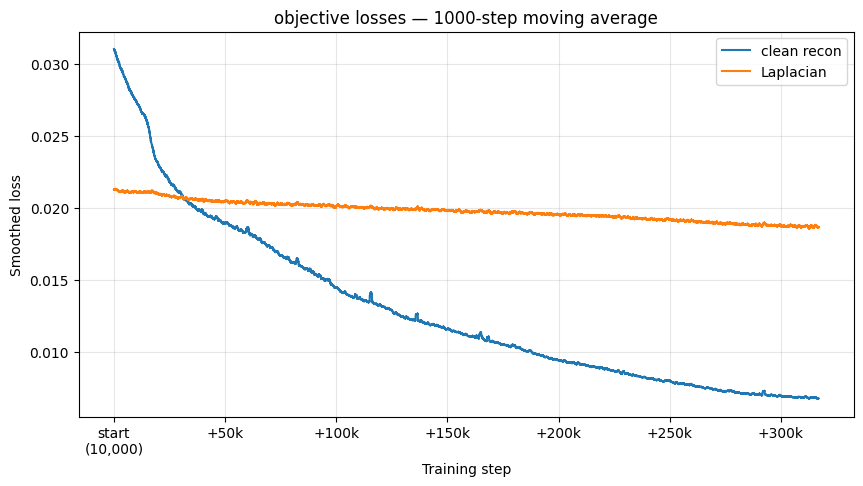

In [356]:
plot_objective_losses(
    window=1000,
    start=10_000
);

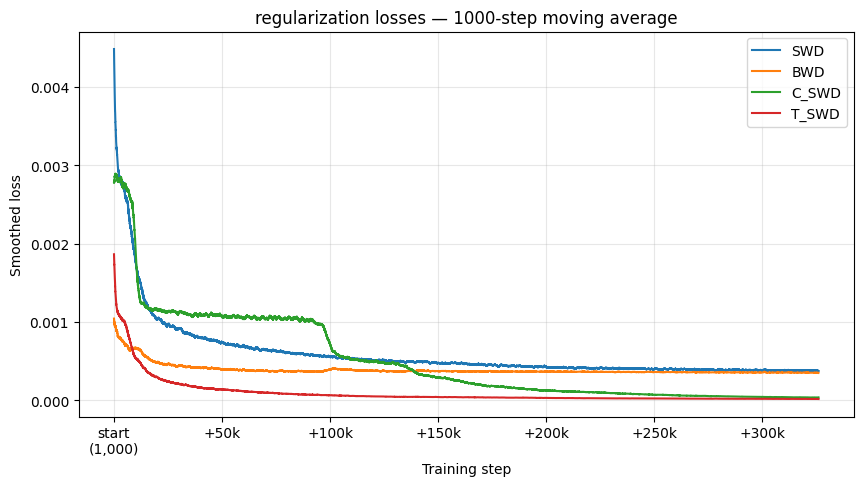

In [358]:
plot_regularization_losses(
    window=1000,
    start=1000,
);

In [324]:
# latent stats: plot_z_dashboard
import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def plot_z_dashboard(
    z,
    n_ref=256,
    sort_by="individual",   # "mean", "std", "individual"
    sort_abs=True,          # True = magnitude, False = signed
    heatmap_percentile=99,  # robust data-dependent color scaling
):
    """
    z: (B, L, D)

    sort_by:
        "mean"       -> both heatmaps use mean-based row/column ordering
        "std"        -> both heatmaps use std-based row/column ordering
        "individual" -> mean heatmap sorts by mean, std heatmap sorts by std

    sort_abs:
        Mean:
            True  -> sort by |mean|, farthest from 0 first
            False -> sort by signed mean, positive -> negative

        Std:
            True  -> sort by |std - 1|, farthest from 1 first
            False -> sort by std - 1, high std -> low std

    heatmap_percentile:
        Robust percentile used for data-dependent heatmap limits.
        Mean stays symmetric around 0.
        Std uses its own low/high percentiles.
    """

    assert sort_by in ("mean", "std", "individual")
    assert 50 < heatmap_percentile <= 100

    z = z.detach().float().cpu()
    assert z.ndim == 3, f"Expected (B, L, D), got {z.shape}"

    B, L, D = z.shape
    assert B >= 2, "Need at least B=2"

    # ------------------------------------------------------------
    # REAL STATS
    # ------------------------------------------------------------

    cell_mean = z.mean(dim=0)               # (L, D)
    cell_std = z.std(dim=0, unbiased=True)  # (L, D)

    # What gets displayed in the side/top charts
    if sort_abs:
        token_mean = cell_mean.abs().mean(dim=1)
        emb_mean = cell_mean.abs().mean(dim=0)

        token_std = (cell_std - 1).abs().mean(dim=1)
        emb_std = (cell_std - 1).abs().mean(dim=0)

    else:
        token_mean = cell_mean.mean(dim=1)
        emb_mean = cell_mean.mean(dim=0)

        token_std = (cell_std - 1).mean(dim=1)
        emb_std = (cell_std - 1).mean(dim=0)

    # ------------------------------------------------------------
    # SORT ORDERS
    # ------------------------------------------------------------

    mean_row_order = token_mean.argsort(descending=True)
    mean_col_order = emb_mean.argsort(descending=True)

    std_row_order = token_std.argsort(descending=True)
    std_col_order = emb_std.argsort(descending=True)

    if sort_by == "mean":
        mean_rows = mean_row_order
        mean_cols = mean_col_order

        std_rows = mean_row_order
        std_cols = mean_col_order

    elif sort_by == "std":
        mean_rows = std_row_order
        mean_cols = std_col_order

        std_rows = std_row_order
        std_cols = std_col_order

    else:  # individual
        mean_rows = mean_row_order
        mean_cols = mean_col_order

        std_rows = std_row_order
        std_cols = std_col_order

    # ------------------------------------------------------------
    # RANDN REFERENCE
    # ------------------------------------------------------------

    ref_token_mean = []
    ref_emb_mean = []
    ref_token_std = []
    ref_emb_std = []

    for _ in range(n_ref):
        r = torch.randn(B, L, D)

        r_mean = r.mean(dim=0)
        r_std = r.std(dim=0, unbiased=True)

        if sort_abs:
            ref_token_mean.append(r_mean.abs().mean(dim=1))
            ref_emb_mean.append(r_mean.abs().mean(dim=0))

            ref_token_std.append((r_std - 1).abs().mean(dim=1))
            ref_emb_std.append((r_std - 1).abs().mean(dim=0))

        else:
            ref_token_mean.append(r_mean.mean(dim=1))
            ref_emb_mean.append(r_mean.mean(dim=0))

            ref_token_std.append((r_std - 1).mean(dim=1))
            ref_emb_std.append((r_std - 1).mean(dim=0))

    ref_token_mean = torch.stack(ref_token_mean)
    ref_emb_mean = torch.stack(ref_emb_mean)
    ref_token_std = torch.stack(ref_token_std)
    ref_emb_std = torch.stack(ref_emb_std)

    def summarize_ref(x):
        return (
            x.mean(dim=0),
            x.quantile(0.05, dim=0),
            x.quantile(0.95, dim=0),
        )

    token_mean_ref, token_mean_lo, token_mean_hi = summarize_ref(ref_token_mean)
    emb_mean_ref, emb_mean_lo, emb_mean_hi = summarize_ref(ref_emb_mean)

    token_std_ref, token_std_lo, token_std_hi = summarize_ref(ref_token_std)
    emb_std_ref, emb_std_lo, emb_std_hi = summarize_ref(ref_emb_std)

    # ------------------------------------------------------------
    # DATA-DEPENDENT HEATMAP LIMITS
    # ------------------------------------------------------------

    q = heatmap_percentile / 100.0
    q_lo = 1.0 - q

    # Mean:
    # keep zero as the visual center, but ignore extreme outliers
    mean_hm_lim = torch.quantile(cell_mean.abs().flatten(), q).item()

    if mean_hm_lim <= 1e-12:
        mean_hm_lim = 1e-12

    mean_hm_lo = -mean_hm_lim
    mean_hm_hi = mean_hm_lim

    # Std:
    # let the actual data determine both ends of the scale.
    # This makes a collapsed 0.000-0.023 latent visibly structured,
    # while a healthy ~0.8-1.2 latent gets its own useful range.
    std_flat = cell_std.flatten()

    std_hm_lo = torch.quantile(std_flat, q_lo).item()
    std_hm_hi = torch.quantile(std_flat, q).item()

    # Std cannot be negative
    std_hm_lo = max(0.0, std_hm_lo)

    # Guard against a perfectly / nearly constant tensor
    if std_hm_hi - std_hm_lo <= 1e-12:
        pad = max(abs(std_hm_hi) * 0.01, 1e-6)
        std_hm_lo = max(0.0, std_hm_lo - pad)
        std_hm_hi = std_hm_hi + pad

    # ------------------------------------------------------------
    # FIGURE
    # ------------------------------------------------------------

    fig = plt.figure(figsize=(18, 8), constrained_layout=True)

    gs = fig.add_gridspec(
        2, 4,
        height_ratios=[1.15, 4.0],
        width_ratios=[1.2, 4.0, 1.2, 4.0],
        wspace=0.05,
        hspace=0.05,
    )

    ax_blank1 = fig.add_subplot(gs[0, 0])
    ax_emb_mean = fig.add_subplot(gs[0, 1])

    ax_blank2 = fig.add_subplot(gs[0, 2])
    ax_emb_std = fig.add_subplot(gs[0, 3])

    ax_token_mean = fig.add_subplot(gs[1, 0])
    ax_mean_hm = fig.add_subplot(gs[1, 1])

    ax_token_std = fig.add_subplot(gs[1, 2])
    ax_std_hm = fig.add_subplot(gs[1, 3])

    ax_blank1.axis("off")
    ax_blank2.axis("off")

    # ------------------------------------------------------------
    # HELPER PLOTS
    # ------------------------------------------------------------

    def plot_top_summary(ax, values, ref, lo, hi, title):
        x = torch.arange(len(values)).numpy()

        ax.bar(x, values.numpy(), color="grey", width=1.0)
        ax.plot(x, ref.numpy(), color="green", linewidth=1.5)

        ax.fill_between(
            x,
            lo.numpy(),
            hi.numpy(),
            color="yellow",
            alpha=0.25,
        )

        ax.set_title(title, fontsize=10)
        ax.set_xlim(-0.5, len(values) - 0.5)

        ax.tick_params(axis="x", labelbottom=False)
        ax.tick_params(axis="y", labelsize=8)

    def plot_side_summary(ax, values, ref, lo, hi, title):
        y = torch.arange(len(values)).numpy()

        ax.barh(y, values.numpy(), color="grey", height=1.0)
        ax.plot(ref.numpy(), y, color="green", linewidth=1.5)

        ax.fill_betweenx(
            y,
            lo.numpy(),
            hi.numpy(),
            color="yellow",
            alpha=0.25,
        )

        ax.set_title(title, fontsize=10)
        ax.set_ylim(len(values) - 0.5, -0.5)

        ax.tick_params(axis="y", labelleft=False)
        ax.tick_params(axis="x", labelsize=8)

    # ------------------------------------------------------------
    # MINI CHARTS
    # ------------------------------------------------------------

    plot_top_summary(
        ax_emb_mean,
        emb_mean[mean_cols],
        emb_mean_ref[mean_cols],
        emb_mean_lo[mean_cols],
        emb_mean_hi[mean_cols],
        "emb-mean",
    )

    plot_side_summary(
        ax_token_mean,
        token_mean[mean_rows],
        token_mean_ref[mean_rows],
        token_mean_lo[mean_rows],
        token_mean_hi[mean_rows],
        "token-mean",
    )

    plot_top_summary(
        ax_emb_std,
        emb_std[std_cols],
        emb_std_ref[std_cols],
        emb_std_lo[std_cols],
        emb_std_hi[std_cols],
        "emb-std",
    )

    plot_side_summary(
        ax_token_std,
        token_std[std_rows],
        token_std_ref[std_rows],
        token_std_lo[std_rows],
        token_std_hi[std_rows],
        "token-std",
    )

    # ------------------------------------------------------------
    # HEATMAPS
    # ------------------------------------------------------------

    mean_heatmap_sorted = cell_mean[mean_rows][:, mean_cols]
    std_heatmap_sorted = cell_std[std_rows][:, std_cols]

    im0 = ax_mean_hm.imshow(
        mean_heatmap_sorted.numpy(),
        aspect="auto",
        interpolation="nearest",
        cmap="coolwarm",
        vmin=mean_hm_lo,
        vmax=mean_hm_hi,
    )

    ax_mean_hm.set_title(
        f"mean heatmap\n"
        f"data [{cell_mean.min().item():.3f}, {cell_mean.max().item():.3f}]   "
        f"color [{mean_hm_lo:.3f}, {mean_hm_hi:.3f}]",
        fontsize=10,
    )

    ax_mean_hm.set_xlabel("Embedding dimension (sorted)")
    ax_mean_hm.set_ylabel("Latent token (sorted)")

    im1 = ax_std_hm.imshow(
        std_heatmap_sorted.numpy(),
        aspect="auto",
        interpolation="nearest",
        cmap="coolwarm",
        vmin=std_hm_lo,
        vmax=std_hm_hi,
    )

    ax_std_hm.set_title(
        f"std heatmap\n"
        f"data [{cell_std.min().item():.3f}, {cell_std.max().item():.3f}]   "
        f"color [{std_hm_lo:.3f}, {std_hm_hi:.3f}]",
        fontsize=10,
    )

    ax_std_hm.set_xlabel("Embedding dimension (sorted)")
    ax_std_hm.set_ylabel("Latent token (sorted)")

    # ------------------------------------------------------------
    # COLORBARS
    # ------------------------------------------------------------

    cbar0 = fig.colorbar(
        im0,
        ax=ax_mean_hm,
        fraction=0.046,
        pad=0.02,
    )
    cbar0.set_label("Mean")

    cbar1 = fig.colorbar(
        im1,
        ax=ax_std_hm,
        fraction=0.046,
        pad=0.02,
    )
    cbar1.set_label("Std")

    # ------------------------------------------------------------
    # TITLE
    # ------------------------------------------------------------

    sign_label = "magnitude" if sort_abs else "signed"

    fig.suptitle(
        f"Latent stats dashboard — B={B}, L={L}, D={D}\n"
        f"sort={sort_by}, {sign_label}"
        f"   |   bars=actual"
        f"   |   green=randn expected"
        f"   |   yellow=randn 5–95%"
        f"   |   heatmaps={heatmap_percentile:g}% robust scale",
        fontsize=13,
    )

    plt.show()

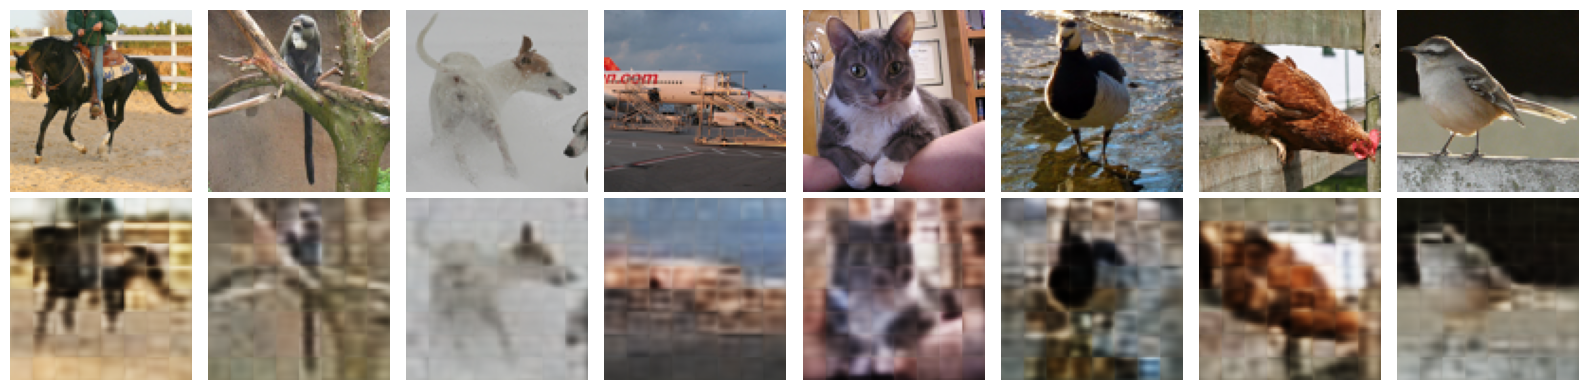

In [336]:
render_reconstruction(masked=False);

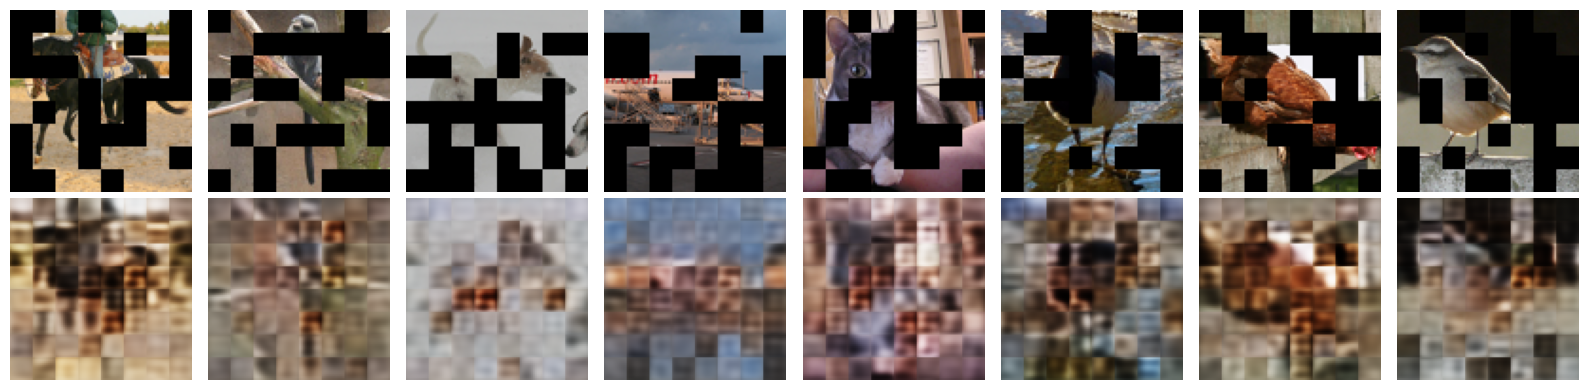

In [343]:
render_reconstruction(masked=True);

In [352]:
# interpolate two images
@torch.no_grad()
def interpolate_two_images(masked=False):

    features, _ = next(iter(train_dataloader))
    features = features[:2].to(device)

    if masked:
        mask = make_mask(features)
        z = encoder(features, mask)
    else:
        z = encoder(features)

    z1, z2 = z.unbind(0)

    weights = torch.linspace(
        0,
        1,
        8,
        device=device,
    )

    rho = F.cosine_similarity(
        z1.flatten(),
        z2.flatten(),
        dim=0,
    )

    z_interpolated = torch.stack([
        torch.lerp(z1, z2, a)
        / torch.sqrt(
            (1 - a) ** 2
            + a ** 2
            + 2 * a * (1 - a) * rho
        )
        for a in weights
    ])

    plot_constructions(
        z_interpolated,
        patch_rows,
        patch_cols,
    )

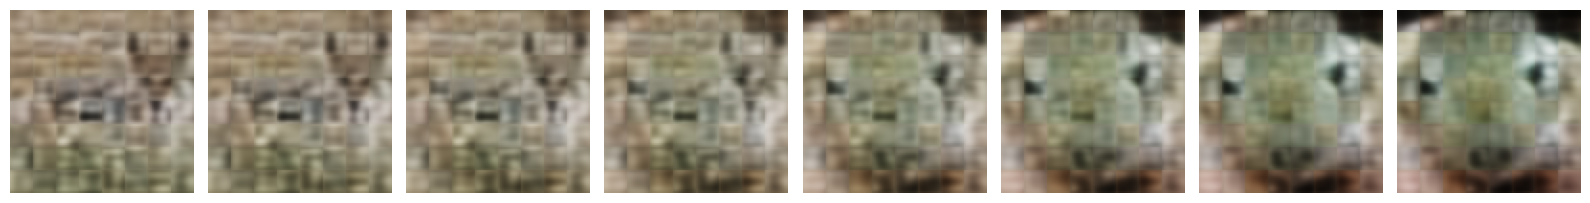

In [353]:
interpolate_two_images(masked=False)

In [346]:
interpolate_two_images(masked=True)

AttributeError: 'tuple' object has no attribute 'unbind'

In [66]:
import torch
import torch.nn.functional as F

@torch.no_grad()
def measure_view_invariance(dataloader, n_batches=20):

    mse_vals = []
    cos_vals = []
    rel_rmse_vals = []
    random_mse_vals = []

    for i, (images, *_) in enumerate(dataloader):
        if i >= n_batches:
            break

        images = images.to(device)

        # same images, clean vs masked
        mask = make_mask(images)

        z_clean, _, _ = encode_z(images)
        z_masked, _, _ = encode_z(images, mask)

        # absolute displacement
        mse = (z_clean - z_masked).square().mean()

        # directional similarity
        cos = F.cosine_similarity(
            z_clean.flatten(1),
            z_masked.flatten(1),
            dim=1,
        ).mean()

        # displacement relative to latent amplitude
        rmse = mse.sqrt()
        z_rms = z_clean.square().mean().sqrt()
        rel_rmse = rmse / z_rms

        # baseline: unrelated clean images
        z_other = z_clean.roll(1, dims=0)
        random_mse = (z_clean - z_other).square().mean()

        mse_vals.append(mse)
        cos_vals.append(cos)
        rel_rmse_vals.append(rel_rmse)
        random_mse_vals.append(random_mse)

    mse = torch.stack(mse_vals).mean().item()
    cos = torch.stack(cos_vals).mean().item()
    rel_rmse = torch.stack(rel_rmse_vals).mean().item()
    random_mse = torch.stack(random_mse_vals).mean().item()

    print(f"clean ↔ masked MSE:     {mse:.6f}")
    print(f"clean ↔ masked cosine:  {cos:.4f}")
    print(f"relative RMSE:          {rel_rmse:.4f}")
    print(f"random-image MSE:       {random_mse:.6f}")
    print(f"invariance / random:    {mse / random_mse:.4f}")

In [279]:
measure_view_invariance(test_dataloader)

clean ↔ masked MSE:     0.000000
clean ↔ masked cosine:  1.0000
relative RMSE:          0.0002
random-image MSE:       0.000000
invariance / random:    2.5124


In [ ]:
train_iter = iter(train_dataloader)

features, labels = next(train_iter)
features = features.to(device)

z, _, _ = encode_z(features)

print(z.shape)

plot_z_dashboard(
    z,
    n_ref=256,
    sort_by="individual",
    sort_abs=True,
)

In [69]:
# latent correlation dashboard: plot_z_correlation_dashboard

import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def plot_z_correlation_dashboard(z):
    """
    z: (B, L, D)

    Channel correlation:
        observations = B * L
        variables    = D channels

    Token correlation:
        observations = B * D
        variables    = L tokens
    """

    z = z.detach().float()
    B, L, D = z.shape

    # --------------------------------------------------
    # CHANNEL <-> CHANNEL CORRELATION
    # pool over batch + tokens
    # --------------------------------------------------
    channel_samples = z.reshape(B * L, D)
    channel_corr = torch.corrcoef(channel_samples.T)

    channel_mask = ~torch.eye(
        D,
        dtype=torch.bool,
        device=z.device,
    )

    channel_offdiag = channel_corr[channel_mask]
    channel_abs_sorted = channel_offdiag.abs().sort(descending=True).values

    # --------------------------------------------------
    # TOKEN <-> TOKEN CORRELATION
    # pool over batch + channels
    # --------------------------------------------------
    token_samples = (
        z.permute(0, 2, 1)
        .reshape(B * D, L)
    )

    token_corr = torch.corrcoef(token_samples.T)

    token_mask = ~torch.eye(
        L,
        dtype=torch.bool,
        device=z.device,
    )

    token_offdiag = token_corr[token_mask]
    token_abs_sorted = token_offdiag.abs().sort(descending=True).values

    # --------------------------------------------------
    # SUMMARY STATS
    # --------------------------------------------------
    ch_mean = channel_offdiag.abs().mean().item()
    ch_median = channel_offdiag.abs().median().item()
    ch_max = channel_offdiag.abs().max().item()

    tok_mean = token_offdiag.abs().mean().item()
    tok_median = token_offdiag.abs().median().item()
    tok_max = token_offdiag.abs().max().item()

    # --------------------------------------------------
    # PLOT
    # --------------------------------------------------
    fig = plt.figure(
        figsize=(16, 9),
        layout="constrained",
    )

    gs = fig.add_gridspec(
        2,
        2,
        height_ratios=(3, 1),
    )

    # CHANNEL HEATMAP
    ax_ch = fig.add_subplot(gs[0, 0])

    im_ch = ax_ch.imshow(
        channel_corr.cpu(),
        vmin=-1,
        vmax=1,
        cmap="coolwarm",
    )

    ax_ch.set_title(
        f"channel correlation\n"
        f"mean |r|={ch_mean:.3f}   "
        f"median={ch_median:.3f}   "
        f"max={ch_max:.3f}"
    )

    ax_ch.set_xlabel("embedding dimension")
    ax_ch.set_ylabel("embedding dimension")

    fig.colorbar(
        im_ch,
        ax=ax_ch,
        label="correlation",
        shrink=0.85,
    )

    # TOKEN HEATMAP
    ax_tok = fig.add_subplot(gs[0, 1])

    im_tok = ax_tok.imshow(
        token_corr.cpu(),
        vmin=-1,
        vmax=1,
        cmap="coolwarm",
    )

    ax_tok.set_title(
        f"token correlation\n"
        f"mean |r|={tok_mean:.3f}   "
        f"median={tok_median:.3f}   "
        f"max={tok_max:.3f}"
    )

    ax_tok.set_xlabel("latent token")
    ax_tok.set_ylabel("latent token")

    fig.colorbar(
        im_tok,
        ax=ax_tok,
        label="correlation",
        shrink=0.85,
    )

    # SORTED CHANNEL CORRELATIONS
    ax_ch_sort = fig.add_subplot(gs[1, 0])

    ax_ch_sort.plot(
        channel_abs_sorted.cpu()
    )

    ax_ch_sort.axhline(
        ch_mean,
        linestyle="--",
        label=f"mean = {ch_mean:.3f}",
    )

    ax_ch_sort.set_title("sorted |channel correlation|")
    ax_ch_sort.set_xlabel("channel pair")
    ax_ch_sort.set_ylabel("|r|")
    ax_ch_sort.set_ylim(0, 1)
    ax_ch_sort.legend()

    # SORTED TOKEN CORRELATIONS
    ax_tok_sort = fig.add_subplot(gs[1, 1])

    ax_tok_sort.plot(
        token_abs_sorted.cpu()
    )

    ax_tok_sort.axhline(
        tok_mean,
        linestyle="--",
        label=f"mean = {tok_mean:.3f}",
    )

    ax_tok_sort.set_title("sorted |token correlation|")
    ax_tok_sort.set_xlabel("token pair")
    ax_tok_sort.set_ylabel("|r|")
    ax_tok_sort.set_ylim(0, 1)
    ax_tok_sort.legend()

    fig.suptitle(
        f"Latent correlation dashboard — "
        f"B={B}, L={L}, D={D}",
        fontsize=15,
    )

    plt.show()

    return {
        "channel_corr": channel_corr.cpu(),
        "token_corr": token_corr.cpu(),

        "channel_mean_abs_corr": ch_mean,
        "channel_median_abs_corr": ch_median,
        "channel_max_abs_corr": ch_max,

        "token_mean_abs_corr": tok_mean,
        "token_median_abs_corr": tok_median,
        "token_max_abs_corr": tok_max,
    }

In [ ]:
plot_z_correlation_dashboard(z);

In [134]:
# Full flattened-latent correlation dashboard
# Matches current SWD space: (B, T*C)

import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def plot_flat_latent_correlation(z):
    """
    z: (B, T, C)

    Measures correlation between every native (token, channel)
    coordinate across B examples.
    """

    z = z.detach().float()

    B, T, C = z.shape
    E = T * C

    # Same flattening as current SWD
    z_flat = z.flatten(1)  # (B, E)

    # Correlation across examples
    x = z_flat - z_flat.mean(dim=0, keepdim=True)
    x = x / x.std(dim=0, keepdim=True).clamp_min(1e-8)

    corr = (x.T @ x) / (B - 1)

    eye = torch.eye(
        E,
        dtype=torch.bool,
        device=z.device,
    )
    off_diag = ~eye

    abs_corr = corr[off_diag].abs()
    sorted_abs = abs_corr.sort(descending=True).values

    mean_abs = abs_corr.mean().item()
    median_abs = abs_corr.median().item()
    max_abs = abs_corr.max().item()

    print(f"B={B} | T={T} | C={C} | flattened dims={E}")
    print(
        f"off-diagonal |r|: "
        f"mean={mean_abs:.4f} | "
        f"median={median_abs:.4f} | "
        f"max={max_abs:.4f}"
    )

    # Full correlation matrix
    plt.figure(figsize=(18, 16))
    plt.imshow(
        corr.cpu(),
        vmin=-1,
        vmax=1,
        cmap="coolwarm",
        interpolation="nearest",
    )
    plt.colorbar(label="correlation")
    plt.title(
        f"Full latent coordinate correlation\n"
        f"B={B}, E={E} | mean |r|={mean_abs:.3f}"
    )
    plt.xlabel("flattened token × channel dim")
    plt.ylabel("flattened token × channel dim")
    plt.show()

    # Sorted correlation strengths
    plt.figure(figsize=(12, 5))
    plt.plot(sorted_abs.cpu())

    plt.axhline(
        mean_abs,
        linestyle="--",
        label=f"mean = {mean_abs:.3f}",
    )

    plt.xlabel("coordinate pair, sorted")
    plt.ylabel("|correlation|")
    plt.title("Sorted full-latent coordinate correlations")
    plt.legend()
    plt.show()

    return {
        "corr": corr.cpu(),
        "mean_abs_corr": mean_abs,
        "median_abs_corr": median_abs,
        "max_abs_corr": max_abs,
    }



In [135]:
# flat_corr_stats = plot_flat_latent_correlation(z)

In [354]:
# probe: reconstruction robustness to latent perturbation

@torch.no_grad()
def plot_z_robustness():

    features, _ = next(iter(train_dataloader))
    features = features[:8].to(device)

    z = encoder(features)
    z_std = z.std()

    noise_fracs = [
        0.00,
        0.01,
        0.02,
        0.05,
        0.10,
        0.20,
        0.50,
    ]

    noise = torch.randn_like(z)

    recons = []
    losses = []

    for frac in noise_fracs:

        z_noisy = z + frac * z_std * noise

        x_hat = decode_z(z_noisy)

        recons.append(x_hat.cpu())

        losses.append(
            F.mse_loss(
                x_hat.float(),
                features.float(),
            ).item()
        )

    # -------------------------
    # image row
    # -------------------------

    fig, axes = plt.subplots(
        1,
        len(noise_fracs),
        figsize=(2 * len(noise_fracs), 2.3),
    )

    for i, frac in enumerate(noise_fracs):

        img = (
            recons[i][0]
            .float()
            .permute(1, 2, 0)
            .clamp(0, 1)
        )

        axes[i].imshow(img)
        axes[i].set_title(f"noise {frac:.2f}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

    # -------------------------
    # robustness curve
    # -------------------------

    plt.figure(figsize=(7, 4))

    plt.plot(
        noise_fracs,
        losses,
        marker="o",
    )

    plt.xlabel("Latent noise / z std")
    plt.ylabel("Reconstruction MSE")
    plt.title("Latent robustness")

    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

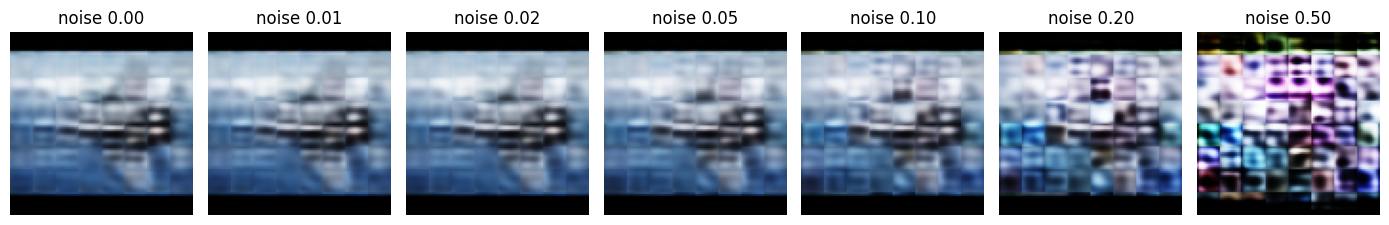

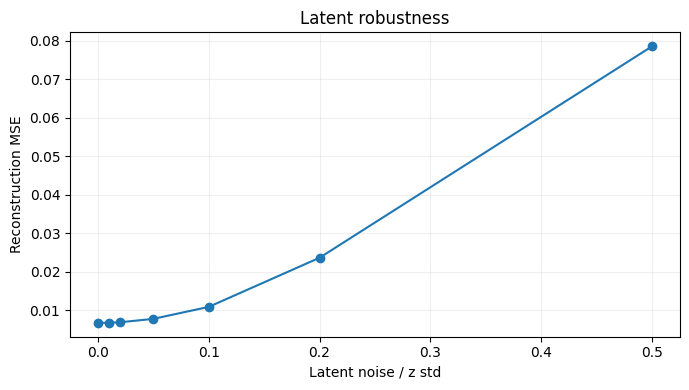

In [355]:

plot_z_robustness()

In [ ]:
# cosine similarity distribution between unrelated encoded images

import torch
import matplotlib.pyplot as plt

encoder.eval()

with torch.no_grad():
    features, _ = next(iter(train_dataloader))
    features = features.to(device)

    z, _, _, _ = encoder(features)      # [B, T, C]

    # treat each image's whole latent as one vector
    z_flat = z.flatten(1)               # [B, T*C]
    z_flat = torch.nn.functional.normalize(z_flat, dim=1)

    # cosine similarity of every image pair
    cosine_matrix = z_flat @ z_flat.T   # [B, B]

    # keep each unique pair once, excluding self-similarity
    mask = torch.triu(
        torch.ones_like(cosine_matrix, dtype=torch.bool),
        diagonal=1
    )

    cosines = cosine_matrix[mask].cpu()


print(f"pairs:  {len(cosines):,}")
print(f"mean:   {cosines.mean():.3f}")
print(f"std:    {cosines.std():.3f}")
print(f"min:    {cosines.min():.3f}")
print(f"median: {cosines.median():.3f}")
print(f"max:    {cosines.max():.3f}")


plt.figure(figsize=(8, 4))
plt.hist(cosines.numpy(), bins=40)
plt.axvline(cosines.mean(), linestyle="--", label=f"mean = {cosines.mean():.3f}")
plt.xlabel("cosine similarity")
plt.ylabel("pair count")
plt.title("Cosine similarity between image latents")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [103]:
# Check whether a few directions dominate image-to-image latent variation
def latent_pca():
    import torch
    import matplotlib.pyplot as plt
    
    with torch.no_grad():
        x = z.detach().flatten(1).float()       # [B, T*C], not normalized
        x = x - x.mean(dim=0, keepdim=True)     # remove the shared mean vector
    
        if min(x.shape) < 2:
            raise ValueError("Need at least two images and two latent coordinates.")
    
        u, s, _ = torch.linalg.svd(x, full_matrices=False)
        energy = s.square()
    
        if energy.sum().item() == 0:
            raise ValueError("All image latents are identical in this batch.")
    
        # Centering leaves at most B-1 independent directions
        n = min(x.shape[0] - 1, x.shape[1])
        share = (energy[:n] / energy.sum()).cpu()
        cumulative = share.cumsum(0)
        scores = (u[:, :2] * s[:2]).cpu()       # image positions along PC1 and PC2
    
        effective_dims = 1 / share.square().sum()
        dims_90 = torch.searchsorted(cumulative, 0.90).item() + 1
    
    print(f"Images: {x.shape[0]} | Flattened dimensions: {x.shape[1]:,}")
    print(f"Top direction: {share[0]:.1%} of centered variation")
    print(f"Top 2 directions: {share[:2].sum():.1%}")
    print(f"Top 5 directions: {share[:5].sum():.1%}")
    print(f"Directions needed for 90%: {dims_90}")
    print(f"Effective dimensions (participation ratio): {effective_dims:.1f}")
    print(f"Batch can reveal at most {n} independent directions.")
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    k = min(20, n)
    axes[0].bar(range(1, k + 1), 100 * share[:k].numpy())
    axes[0].set(
        title="Variation carried by each direction",
        xlabel="Principal direction",
        ylabel="Share of variation (%)",
    )
    
    axes[1].plot(range(1, n + 1), 100 * cumulative.numpy())
    axes[1].axhline(90, color="gray", linestyle="--", label="90%")
    axes[1].set(
        title="Cumulative variation",
        xlabel="Number of directions",
        ylabel="Variation captured (%)",
        ylim=(0, 102),
    )
    axes[1].legend()
    
    axes[2].scatter(scores[:, 0], scores[:, 1], s=28, alpha=0.65)
    axes[2].axhline(0, color="gray", linewidth=0.7)
    axes[2].axvline(0, color="gray", linewidth=0.7)
    axes[2].set(
        title="Each dot is one image",
        xlabel=f"PC1 ({share[0]:.1%})",
        ylabel=f"PC2 ({(energy[1] / energy.sum()).item():.1%})",
    )
    axes[2].set_aspect("equal", adjustable="box")
    
    for ax in axes:
        ax.grid(alpha=0.2)
    
    plt.tight_layout()
    plt.show()

In [ ]:
latent_pca()

In [190]:
#def latent ablations
import math
import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def probe_latent_ablations(
    image_index=0,
    n_svd=8,
    token_counts=(1, 2, 4, 8, 12, 16, 20, 24),
    channel_counts=(1, 2, 4, 8, 16, 32, 48, 64),
    seed=42,
):
    if n_svd < 1:
        raise ValueError("n_svd must be >= 1")

    modes = [
        (module, module.training)
        for model in (encoder, decoder)
        for module in model.modules()
    ]
    probe_device = next(encoder.parameters()).device

    try:
        encoder.eval()
        decoder.eval()

        # Grab one source image + latent from first batch.
        for batch_i, (images, _) in enumerate(train_dataloader):
            images = images.to(probe_device)
            enc = encoder(images)

            if not 0 <= image_index < len(images):
                raise ValueError("image_index is outside the first batch.")

            source_image = images[image_index].float().cpu()
            source_z = z[image_index:image_index + 1].float()   # (1, T, D)
            probe_rows = enc.patch_rows
            probe_cols = enc.patch_cols
            break
        else:
            raise ValueError("train_dataloader is empty.")

        z = source_z
        _, T, D = z.shape
        target_norm = z.norm()

        # Per-image SVD on the latent matrix z[0] with shape (T, D).
        z2d = z[0]
        U, S, Vh = torch.linalg.svd(z2d, full_matrices=False)

        n_svd = min(n_svd, len(S))
        energy_fraction = S.square() / S.square().sum().clamp_min(1e-12)

        # Rank-1 components, each shaped (1, T, D)
        components = []
        for i in range(n_svd):
            comp = (
                S[i]
                * U[:, i:i+1]
                * Vh[i:i+1, :]
            )
            components.append(comp.unsqueeze(0))
        components = torch.cat(components, dim=0)          # (n_svd, T, D)
        cumulative = components.cumsum(dim=0)              # top-k reconstruction

        def norm_match(values):
            return values * (
                target_norm / values.norm().clamp_min(1e-12)
            )

        rng = torch.Generator(device="cpu").manual_seed(seed)
        token_order = torch.randperm(T, generator=rng).to(probe_device)
        channel_order = torch.randperm(D, generator=rng).to(probe_device)

        def valid_counts(counts, size):
            return sorted({
                min(int(k), size)
                for k in counts
                if int(k) > 0
            })

        token_counts = valid_counts(token_counts, T)
        channel_counts = valid_counts(channel_counts, D)

        def decode(probe_z):
            return decoder(
                probe_z.to(source_z.dtype)
            )[0].float().cpu()

        def select(values, axis, indices):
            selected = torch.zeros_like(values)
            if axis == "Token":
                selected[:, indices, :] = values[:, indices, :]
            else:
                selected[:, :, indices] = values[:, :, indices]
            return selected

        def comp_label(i):
            return f"C{i + 1}"

        full_recon = decode(z)
        zero_recon = decode(torch.zeros_like(z))
        
        sections = {}

        def add_section(name, probes):
            sections[name] = [
                (title, decode(probe_z))
                for title, probe_z in probes
            ]

        # SVD ablations: remove top-k components from raw z, no renorm.
        add_section(
            "SVD ablate: cumulative",
            [
                (
                    f"Remove {comp_label(i)}",
                    z - cumulative[i:i + 1],
                )
                for i in range(n_svd)
            ],
        )


        # SVD only: individual, renorm to full latent norm.
        add_section(
            "SVD only: individual | 1× norm",
            [
                (
                    f"{comp_label(i)} only\n"
                    f"{energy_fraction[i].item():.1%} energy",
                    norm_match(components[i:i + 1]),
                )
                for i in range(n_svd)
            ],
        )

        for axis, order, counts in [
            ("Token", token_order, token_counts),
            ("Channel", channel_order, channel_counts),
        ]:
            # Natural ablation: zero selected entries, no renorm.
            add_section(
                f"{axis} ablate: cumulative",
                [
                    (
                        f"Remove {k}/{len(order)}",
                        z - select(z, axis, order[:k]),
                    )
                    for k in counts
                ],
            )

            # Keep only selected entries, renorm to full latent norm.

            add_section(
                f"{axis} only: individual | 1× norm",
                [
                    (
                        f"{axis} {i}",
                        norm_match(select(z, axis, [i])),
                    )
                    for i in range(len(order))
                ],
            )

    finally:
        for module, was_training in modes:
            module.training = was_training

    def show_grid(title, items, ncols=8, cell_size=2):
        if not items:
            return

        ncols = min(ncols, len(items))
        nrows = math.ceil(len(items) / ncols)

        fig, axes = plt.subplots(
            nrows,
            ncols,
            figsize=(cell_size * ncols, cell_size * nrows + 0.7),
            squeeze=False,
            layout="constrained",
        )

        for ax, (label, img) in zip(axes.flat, items):
            ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
            ax.set_title(label, fontsize=9)

        for ax in axes.flat:
            ax.axis("off")

        fig.suptitle(title)
        plt.show()

    show_grid(
        "Reference",
        [
            ("Input", source_image),
            ("Full reconstruction", full_recon),
            ("Zero latent", zero_recon),
        ],
        ncols=3,
        cell_size=2.5,
    )

    for name, items in sections.items():
        show_grid(name, items)

    print(f"Single-image SVD | latent: {T} tokens × {D} channels")
    print(
        f"First {n_svd} components explain "
        f"{energy_fraction[:n_svd].sum().item():.1%} of latent energy"
    )
    print("Token subset order:", token_order.cpu().tolist())
    print("Channel subset order:", channel_order.cpu().tolist())
    print("ABLATE: selected information is zeroed with no renorm.")
    print("ONLY: selected information is kept and scaled to full latent norm.")

    return {
        "input": source_image,
        "full_recon": full_recon,
        "zero_recon": zero_recon,
        "sections": sections,
        "z": z.cpu(),
        "svd_u": U[:, :n_svd].cpu(),
        "svd_s": S[:n_svd].cpu(),
        "svd_vh": Vh[:n_svd].cpu(),
        "svd_components": components.cpu(),
        "energy_fraction": energy_fraction[:n_svd].cpu(),
        "token_order": token_order.cpu(),
        "channel_order": channel_order.cpu(),
    }



In [ ]:

ablation_results = probe_latent_ablations()

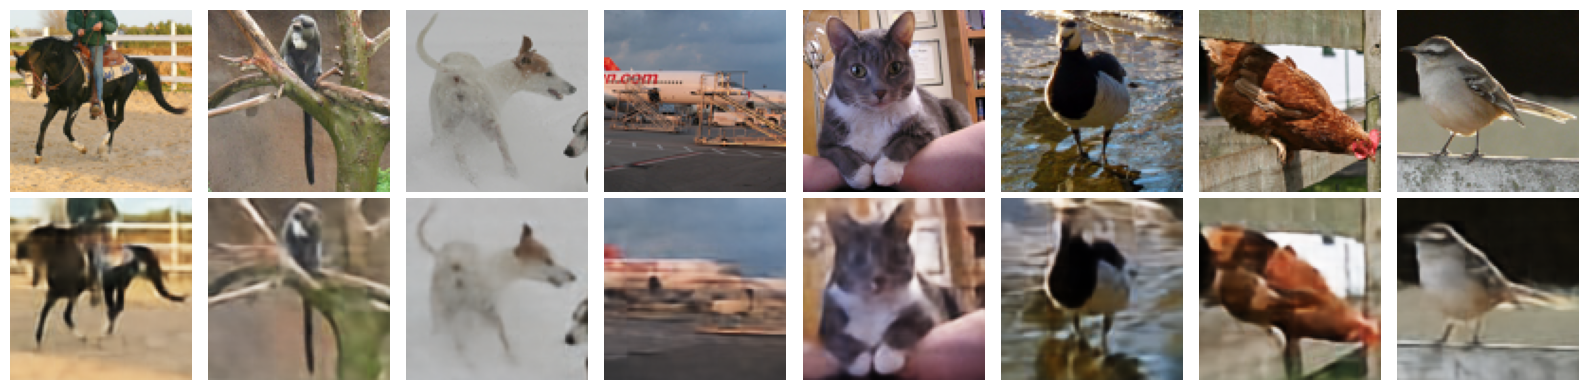

In [218]:
render_reconstruction(masked=False)

In [ ]:
# Compare current LIVE run vs 4 newest saved runs with clean recon history

from pathlib import Path
import torch
import numpy as np
import matplotlib.pyplot as plt

def moving_average(x, window=100):
    x = np.asarray(x, dtype=float)

    if len(x) < window:
        return x

    return np.convolve(
        x,
        np.ones(window) / window,
        mode="valid",
    )


clean_keys = [
    "clean_term",
    "clean_recon",
    "clean_recon_loss",
    "recon",
    "recon_loss",
    "train_loss_clean",
    "clean_loss",
]


def find_clean_metric(history):
    for key in clean_keys:
        if key in history and len(history[key]) > 0:
            return key, history[key]

    return None, None


# --------------------------------------------------
# FIND 4 NEWEST SAVED RUNS WITH USABLE HISTORY
# --------------------------------------------------

run_files = sorted(
    Path("training_runs").glob("*.pt"),
    key=lambda p: p.stat().st_mtime,
    reverse=True,
)

saved = []

for path in run_files:
    run = torch.load(
        path,
        map_location="cpu",
        weights_only=False,
    )

    if not isinstance(run, dict):
        continue

    history = run.get("history", run)

    if not isinstance(history, dict):
        continue

    key, values = find_clean_metric(history)

    if key is None:
        continue

    saved.append((path.stem, key, values))

    if len(saved) == 4:
        break


# --------------------------------------------------
# LIVE RUN
# --------------------------------------------------

live_history = get_metrics_lists()

live_key, live_values = find_clean_metric(live_history)

if live_key is None:
    raise KeyError(
        f"No clean recon metric found in live history.\n"
        f"Available keys:\n{list(live_history.keys())}"
    )


# --------------------------------------------------
# PLOT
# --------------------------------------------------

plt.figure(figsize=(13, 7))

# saved runs
for name, key, values in reversed(saved):

    if torch.is_tensor(values):
        values = values.detach().cpu().numpy()

    smooth = moving_average(values, window=100)

    plt.plot(
        smooth,
        alpha=0.8,
        label=name,
    )


# live run
if torch.is_tensor(live_values):
    live_values = live_values.detach().cpu().numpy()

live_smooth = moving_average(
    live_values,
    window=100,
)

plt.plot(
    live_smooth,
    linewidth=3,
    label="LIVE 5M",
)

plt.xlabel("training step")
plt.ylabel("clean reconstruction loss")
plt.title("Clean reconstruction — recent saved runs vs LIVE 5M")
plt.grid(alpha=0.25)
plt.legend()
plt.show()


print("Saved comparison runs:")
for name, key, _ in saved:
    print(f"  {name} [{key}]")

print(f"\nLIVE 5M [{live_key}]")

In [191]:
################ EXPORT REFINED EXPORTED AE ################

import os
from pathlib import Path
import torch


def export_refined_ae(
    encoder,
    decoder,
    example_images,
    name,
    save_root=None,
):
    if save_root is None:
        save_root = os.environ["ML_MODELS"]

    save_dir = Path(save_root) / name
    save_dir.mkdir(parents=True, exist_ok=True)

    # >1 example so batch dimension can be dynamic
    example_images = example_images[:2]

    batch_dim = torch.export.Dim(
        "batch",
        min=1,
        max=8192,
    )

    # --------------------------------
    # Get example latent
    # --------------------------------
    with torch.no_grad():
        z = encoder(example_images)

    # --------------------------------
    # Encoder
    #
    # Export:
    #     image -> z
    # --------------------------------
    encoder_ep = torch.export.export(
        encoder,
        (example_images,),
        dynamic_shapes=(
            {0: batch_dim},
        ),
        strict=False,
    )

    # --------------------------------
    # Decoder
    #
    # Export:
    #     z -> image
    # --------------------------------
    decoder_ep = torch.export.export(
        decoder,
        (z,),
        dynamic_shapes=(
            {0: batch_dim},
        ),
        strict=False,
    )

    # --------------------------------
    # Save
    # --------------------------------
    torch.export.save(
        encoder_ep,
        save_dir / "encoder.pt2",
    )

    torch.export.save(
        decoder_ep,
        save_dir / "decoder.pt2",
    )

    print(f"Exported refined AE to {save_dir}")

In [230]:
## EXPORT REFINED AE ##

ae_name = "ae_5M_jepa_recon_no_dec_latent_slots_210e"

images, _ = next(iter(train_dataloader))
images = images[:2].to(device)

export_refined_ae(
    encoder,
    decoder,
    images,
    ae_name,
)

Exported refined AE to <home>/jupyterlab/Jupyter_AI/models/ae_5M_jepa_recon_no_dec_latent_slots_210e


In [45]:
import os
import torch

name = '2026-09-13_230040_ae_400k_jepa_recon_no_dec_latent_slots.pt' # pre-decoder refinement

In [46]:
# load models

import os
from pathlib import Path

checkpoint_path = (
    Path(os.environ["ML_CHECKPOINTS"])
    / "ae"
    / name
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True,
)

encoder.load_state_dict(checkpoint["encoder"])
decoder.load_state_dict(checkpoint["decoder"])

print(f"Loaded checkpoint from {checkpoint_path}")

Loaded checkpoint from <home>/projects/Jupyter_AI/checkpoints/ae/2026-09-13_230040_ae_400k_jepa_recon_no_dec_latent_slots.pt


In [76]:
# save models

import os
from pathlib import Path

checkpoint_dir = Path(os.environ["ML_CHECKPOINTS"]) / "ae"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = checkpoint_dir / name

torch.save(
    {
        "encoder": encoder.state_dict(),
        "decoder": decoder.state_dict(),
    },
    checkpoint_path,
)

print(f"Saved checkpoint to {checkpoint_path}")

Saved checkpoint to <home>/jupyter/checkpoints/ae/ae_5M_jepa_recon_tswd.pt


In [39]:
# sync models + checkpoints   spark <---> pc

import os
import socket
import subprocess
from pathlib import Path


def sync_models():

    # ML_MODELS should be something like:
    # PC:    <home>/jupyter/models
    # Spark: <home>/jupyterlab/Jupyter_AI/models
    local_models = Path(os.environ["ML_MODELS"])
    local_root = local_models.parent

    hostname = socket.gethostname()

    if hostname == "gpu-box":
        remote_root = "pc:<home>/jupyter"

    elif hostname == "pc":
        remote_root = "gpu-box:<home>/jupyterlab/Jupyter_AI"

    else:
        raise RuntimeError(f"Unknown host: {hostname}")

    rsync_args = [
        "rsync",
        "-a",
        "--update",
        "--partial",
        "--itemize-changes",
    ]

    for folder in [
        "models",
        "checkpoints",
    ]:
        local_dir = local_root / folder
        local_dir.mkdir(parents=True, exist_ok=True)

        remote_dir = f"{remote_root}/{folder}/"

        print(f"\nSyncing {folder}...")

        # Send newer local files
        subprocess.run(
            rsync_args + [
                f"{local_dir}/",
                remote_dir,
            ],
            check=True,
        )

        # Fetch newer remote files
        subprocess.run(
            rsync_args + [
                remote_dir,
                f"{local_dir}/",
            ],
            check=True,
        )

    print(f"\nModels + checkpoints synced: {local_root}")

In [40]:
sync_models()


Syncing models...
.d..t...... ./

Syncing checkpoints...

Models + checkpoints synced: <home>/jupyter


In [186]:
# LOAD EXACT AE USED BY LATENT FLOW

import os
from pathlib import Path
import torch

ae_name = "ae_5M_jepa_recon_swd_200e_refined"

ae_dir = Path(os.environ["ML_MODELS"]) / ae_name

encoder = torch.export.load(
    ae_dir / "encoder.pt2"
).module().to(device)

decoder = torch.export.load(
    ae_dir / "decoder.pt2"
).module().to(device)

# frozen encoder, trainable decoder for refinement
encoder.requires_grad_(False)
decoder.requires_grad_(True)

# detach decoder storage from torch.export archive
# before optimizer updates it
with torch.no_grad():
    for p in decoder.parameters():
        p.data = p.data.clone()

    for b in decoder.buffers():
        b.data = b.data.clone()

print(f"Loaded AE: {ae_name}")
print(
    "encoder params:",
    sum(p.numel() for p in encoder.parameters())
)
print(
    "decoder params:",
    sum(p.numel() for p in decoder.parameters())
)

Loaded AE: ae_5M_jepa_recon_swd_200e_refined
encoder params: 2774400
decoder params: 2774640


In [187]:
# detach decoder parameters/buffers from torch.export archive storage
with torch.no_grad():
    for p in decoder.parameters():
        p.data = p.data.clone()

    for b in decoder.buffers():
        b.data = b.data.clone()

encoder.requires_grad_(False)
decoder.requires_grad_(True)

GraphModule(
  (decoder): Module(
    (emb_in_proj): Module()
    (token_in_proj): Module()
    (core_transformer): Module(
      (blocks): Module(
        (0): Module(
          (MHA): Module(
            (norm): Module()
            (QKV): Module()
            (out_proj): Module()
          )
          (MLP): Module(
            (net): Module(
              (0): Module()
              (1): Module()
              (3): Module()
            )
          )
        )
        (1): Module(
          (MHA): Module(
            (norm): Module()
            (QKV): Module()
            (out_proj): Module()
          )
          (MLP): Module(
            (net): Module(
              (0): Module()
              (1): Module()
              (3): Module()
            )
          )
        )
        (2): Module(
          (MHA): Module(
            (norm): Module()
            (QKV): Module()
            (out_proj): Module()
          )
          (MLP): Module(
            (net): Module(
            